In [1]:
import os
import re
from urllib.parse import quote

import numpy as np
import pandas as pd

from dotenv import load_dotenv
from sqlalchemy import create_engine, text, bindparam

from rdkit import Chem, RDLogger, rdBase

import umap
from sklearn.preprocessing import QuantileTransformer

import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Rectangle, FancyArrow
from matplotlib.ticker import FuncFormatter

import seaborn as sns

from upsetplot import UpSet, from_memberships

In [2]:
source_index = pd.read_excel(r"./data/ROCKS_Inventory_Index.xlsx")
tickets = list(source_index['Final Ticket Name'])

curation_data = pd.read_parquet(r"./parquets/curation_data_df.parquet")

In [3]:
curation_data['identifier_type'].drop_duplicates().dropna()

0                   cas_rn
5                  synonym
15                   ec_no
573009     systematic_name
2200668             smiles
2226728              inchi
3293937             dtxsid
3294431           inchikey
3386722        pubchem_cid
Name: identifier_type, dtype: category
Categories (9, str): ['cas_rn', 'dtxsid', 'ec_no', 'inchi', ..., 'pubchem_cid', 'smiles', 'synonym', 'systematic_name']

In [4]:
number_of_sources = curation_data['ticket_name'].drop_duplicates().shape[0]
number_of_records = curation_data['record_id'].drop_duplicates().shape[0]
number_of_jurisdictions = source_index['Country or Jurisdiction '].dropna().drop_duplicates().shape[0]

print(f"{number_of_sources} Sources \n{number_of_records} Records")

129 Sources 
1104145 Records


In [5]:
curation_data.loc[curation_data['cichem_id'].isna()]

,ticket_name,record_id,match_id,identifier_type,identifier_value,primary_name,cichem_id,average_mass,inchikey
4030,ROCKS_2026_I16_vietnam-in-commerce,8221354,NaN,cas_rn,20243-18-9,NaN,NaN,NaN,NaN
4031,ROCKS_2026_I16_vietnam-in-commerce,8221354,NaN,synonym,Lussatite,NaN,NaN,NaN,NaN
4032,ROCKS_2026_I16_vietnam-in-commerce,8221354,NaN,synonym,Lussatite,NaN,NaN,NaN,NaN
14180,ROCKS_2026_I16_vietnam-in-commerce,8222535,NaN,cas_rn,22990-19-8,NaN,NaN,NaN,NaN
14181,ROCKS_2026_I16_vietnam-in-commerce,8222535,NaN,synonym,"1,2,3,4-Tetrahydro-1-phenylisoquinoline",NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
6983336,ROCKS_2026_F9_FOODCONTACTSDB,9106024,NaN,systematic_name,4-Aminobut-2-enoic acid,NaN,NaN,NaN,NaN
7380366,ROCKS_2026_I12_south-korea-keci,7805718,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7380367,ROCKS_2026_I12_south-korea-keci,7805656,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7380368,ROCKS_2026_I12_south-korea-keci,7805749,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:


df = (
    curation_data[
        ["ticket_name", "record_id", "identifier_type", "identifier_value"]
    ]
    .dropna(subset=["record_id", "identifier_type"])
    .drop_duplicates(subset=["record_id", "identifier_type"])
)

# One set of identifier types per record
record_sets = (
    df.groupby("record_id")["identifier_type"]
      .apply(lambda x: tuple(sorted(set(x))))
)

# Panel A: count records by identifier type
type_counts = (
    df.groupby("identifier_type")["record_id"]
      .nunique()
      .sort_values(ascending=False)
)

# Panel B: count records by exact identifier-type combination
combo_counts = (
    record_sets.value_counts()
      .rename_axis("identifier_combo")
      .reset_index(name="record_count")
)

combo_counts["combo_label"] = combo_counts["identifier_combo"].apply(
    lambda x: " + ".join(x)
)

combo_counts.head(5)

,identifier_combo,record_count,combo_label
0,"(cas_rn, synonym)",541298,cas_rn + synonym
1,"(cas_rn, ec_no, synonym)",230311,cas_rn + ec_no + synonym
2,"(synonym,)",76314,synonym
3,"(inchikey, pubchem_cid, smiles, synonym)",67291,inchikey + pubchem_cid + smiles + synonym
4,"(cas_rn, dtxsid, synonym)",65841,cas_rn + dtxsid + synonym


In [7]:
curated_data = pd.read_parquet(r"./parquets/curated_data.parquet",)
structured_cichems = curated_data[['cichem_id', 'inchikey']].dropna()['cichem_id'].drop_duplicates()
curated_data['inchikey'].dropna().drop_duplicates().shape[0]/238602 # number of chemicals in total ROCKS collection

0.6983596114030897

In [8]:
match_data = pd.read_parquet(r"./parquets/match_data.parquet")

In [9]:
match_data

,ticket_name,record_id,primary_name,record_match,average_mass,identifier_match,matched_cichem,inchikey
0,ROCKS_2026_I11b_philippines-piccs-supp,7903248,"Carbonic acid, 2-[(1-amino-9,10-dihydro-4-hydr...",CICHEM000673616,419.389008,cas_rn,CICHEM000673616,GLLYQJVICPAIGW-UHFFFAOYSA-N
1,ROCKS_2026_I11b_philippines-piccs-supp,7903249,"Formaldehyde, reaction products with bisphenol...",CICHEM001022607,NaN,cas_rn,CICHEM001022607,NaN
2,ROCKS_2026_I11b_philippines-piccs-supp,7903250,"1-Propanol, 2-[2-(benzoyloxy)propoxy]-, 1-benz...",CICHEM008649212,342.390991,cas_rn,CICHEM008649212,LXODQLXKQIJVNK-UHFFFAOYNA-N
3,ROCKS_2026_I11b_philippines-piccs-supp,7903251,CICHEM013961057,CICHEM013961057,NaN,cas_rn,CICHEM013961057,NaN
4,ROCKS_2026_I11b_philippines-piccs-supp,7903252,"Tar bases, quinoline derivs., 1-(chloromethyl)...",CICHEM001079433,NaN,cas_rn,CICHEM001079433,NaN
...,...,...,...,...,...,...,...,...
2367571,ROCKS_2026_I7c_japan-notif,7911917,NaN,NaN,NaN,NaN,NaN,NaN
2367572,ROCKS_2026_C2_cosing,8165252,NaN,NaN,NaN,NaN,NaN,NaN
2367573,ROCKS_2026_I5a_china-2013,7716248,NaN,NaN,NaN,NaN,NaN,NaN
2367574,ROCKS_2026_I13_taiwan-tcsi,7831137,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
columns_to_aggregate = [
    "identifier_match",
    "matched_cichem",
    "record_match",
    "ticket_name",
]

match_data = match_data.copy()
match_data[columns_to_aggregate] = match_data[columns_to_aggregate].astype("object")

pivoted_records = (
    match_data
    .groupby("record_id", dropna=False)
    .agg(
        matches=(
            "identifier_match",
            lambda x: sorted(set(x.dropna()))
        ),
        matched_chems=(
            "matched_cichem",
            lambda x: sorted(set(x.dropna()))
        ),
        record_match=(
            "record_match",
            lambda x: x.dropna().iloc[0] if not x.dropna().empty else None
        ),
        ticket_name=(
            "ticket_name",
            lambda x: sorted(set(x.dropna()))
        ),
    )
    .reset_index()
)

pivoted_records


,record_id,matches,matched_chems,record_match,ticket_name
0,7264104,[],[],NaN,[ROCKS_2026_F1_food-substances-and-additives-AUS]
1,7264105,[],[],NaN,[ROCKS_2026_F1_food-substances-and-additives-AUS]
2,7264106,[],[],NaN,[ROCKS_2026_F1_food-substances-and-additives-AUS]
3,7264107,[],[],NaN,[ROCKS_2026_F1_food-substances-and-additives-AUS]
4,7264108,[],[],NaN,[ROCKS_2026_F1_food-substances-and-additives-AUS]
...,...,...,...,...,...
1104140,9239111,"[cas_rn, dtxsid, name_synonym]",[CICHEM008731606],CICHEM008731606,[ROCKS_2026_B19_mmdbbio]
1104141,9239112,"[dtxsid, name_synonym]",[CICHEM008659948],CICHEM008659948,[ROCKS_2026_B19_mmdbbio]
1104142,9239113,"[cas_rn, dtxsid, name_primary]",[CICHEM000527234],CICHEM000527234,[ROCKS_2026_B19_mmdbbio]
1104143,9239114,"[cas_rn, dtxsid, name_synonym]",[CICHEM010030385],CICHEM010030385,[ROCKS_2026_B19_mmdbbio]


In [11]:
pivoted_records['number_match_chems'] = pivoted_records['matched_chems'].apply(lambda x:len(x))
pivoted_records

,record_id,matches,matched_chems,record_match,ticket_name,number_match_chems
0,7264104,[],[],NaN,[ROCKS_2026_F1_food-substances-and-additives-AUS],0
1,7264105,[],[],NaN,[ROCKS_2026_F1_food-substances-and-additives-AUS],0
2,7264106,[],[],NaN,[ROCKS_2026_F1_food-substances-and-additives-AUS],0
3,7264107,[],[],NaN,[ROCKS_2026_F1_food-substances-and-additives-AUS],0
4,7264108,[],[],NaN,[ROCKS_2026_F1_food-substances-and-additives-AUS],0
...,...,...,...,...,...,...
1104140,9239111,"[cas_rn, dtxsid, name_synonym]",[CICHEM008731606],CICHEM008731606,[ROCKS_2026_B19_mmdbbio],1
1104141,9239112,"[dtxsid, name_synonym]",[CICHEM008659948],CICHEM008659948,[ROCKS_2026_B19_mmdbbio],1
1104142,9239113,"[cas_rn, dtxsid, name_primary]",[CICHEM000527234],CICHEM000527234,[ROCKS_2026_B19_mmdbbio],1
1104143,9239114,"[cas_rn, dtxsid, name_synonym]",[CICHEM010030385],CICHEM010030385,[ROCKS_2026_B19_mmdbbio],1


In [12]:
number_of_records = pivoted_records.shape[0]
number_of_unique_chemical_entities = pivoted_records['record_match'].dropna().drop_duplicates().shape[0]
unmapped_records = pivoted_records.loc[pivoted_records['record_match'].isna()].shape[0]

print(f"Number of source tickets: {number_of_sources:,}\nNumber of individual records {number_of_records:,}\nNumber of unique entities {number_of_unique_chemical_entities:,}\nNumber of unmapped records: {unmapped_records:,}")

Number of source tickets: 129
Number of individual records 1,104,145
Number of unique entities 238,602
Number of unmapped records: 189,199


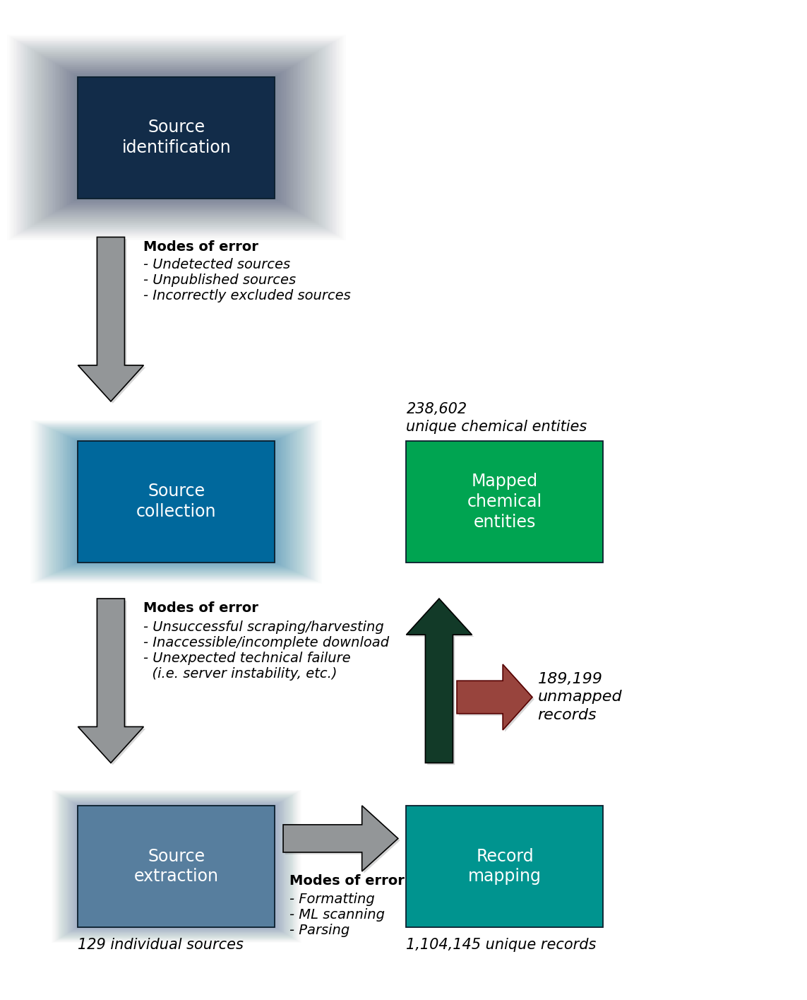

In [13]:
# ============================================================
# Drawing helpers
# ============================================================

def add_soft_box(
    ax,
    x,
    y,
    width,
    height,
    text,
    facecolor,
    edgecolor="#0A1E2D",
    fontsize=17,
    blur_layers=35,
    blur_x=0.018,
    blur_y=0.010,
    blur_alpha=0.018,
    zorder=5,
):
    """
    Draw a sharp box surrounded by anisotropic layered soft edges.

    The larger horizontal expansion approximates the PowerPoint-style
    blur visible around the upstream source boxes.
    """

    # Draw from largest/faintest layer toward smallest/darkest layer
    for layer in range(blur_layers, 0, -1):
        fraction = layer / blur_layers

        expand_x = layer * blur_x
        expand_y = layer * blur_y

        ax.add_patch(
            Rectangle(
                (x - expand_x, y - expand_y),
                width + (2 * expand_x),
                height + (2 * expand_y),
                facecolor=facecolor,
                edgecolor="none",
                alpha=blur_alpha * (1 - 0.35 * fraction),
                zorder=zorder - 2,
                clip_on=False,
            )
        )

    # Sharp central box
    box = Rectangle(
        (x, y),
        width,
        height,
        facecolor=facecolor,
        edgecolor=edgecolor,
        linewidth=1.3,
        zorder=zorder,
    )
    ax.add_patch(box)

    ax.text(
        x + width / 2,
        y + height / 2,
        text,
        ha="center",
        va="center",
        color="white",
        fontsize=fontsize,
        linespacing=1.25,
        zorder=zorder + 1,
    )


def add_box(
    ax,
    x,
    y,
    width,
    height,
    text,
    facecolor,
    edgecolor="#0A1E2D",
    fontsize=17,
    zorder=5,
):
    """Draw a standard crisp rectangular process box."""

    box = Rectangle(
        (x, y),
        width,
        height,
        facecolor=facecolor,
        edgecolor=edgecolor,
        linewidth=1.3,
        zorder=zorder,
    )
    ax.add_patch(box)

    ax.text(
        x + width / 2,
        y + height / 2,
        text,
        ha="center",
        va="center",
        color="white",
        fontsize=fontsize,
        linespacing=1.25,
        zorder=zorder + 1,
    )


def add_arrow(
    ax,
    x,
    y,
    dx,
    dy,
    color="#939698",
    width=0.42,
    head_width=1.05,
    head_length=0.55,
    edgecolor="#000000",
    zorder=4,
):
    """Draw a block arrow with a subtle drop shadow."""

    arrow = FancyArrow(
        x,
        y,
        dx,
        dy,
        width=width,
        head_width=head_width,
        head_length=head_length,
        length_includes_head=True,
        facecolor=color,
        edgecolor=edgecolor,
        linewidth=1.2,
        zorder=zorder,
    )

    arrow.set_path_effects(
        [
            pe.SimplePatchShadow(
                offset=(2, -2),
                shadow_rgbFace=(0, 0, 0),
                alpha=0.16,
            ),
            pe.Normal(),
        ]
    )

    ax.add_patch(arrow)


# ============================================================
# Figure setup
# ============================================================

fig, ax = plt.subplots(figsize=(12, 15))

ax.set_xlim(0, 12)
ax.set_ylim(0, 15)
ax.set_aspect("equal")
ax.axis("off")

# Palette
dark_blue = "#122C49"
medium_blue = "#00689C"
light_blue = "#577E9E"
teal = "#00948F"
dark_green = "#00A451"
red = "#98443D"


# ============================================================
# Upstream source boxes with soft edges
# ============================================================

add_soft_box(
    ax=ax,
    x=1.0,
    y=12.09,
    width=3.0,
    height=1.85,
    text="Source\nidentification",
    facecolor=dark_blue,
    blur_layers=40,
    blur_x=0.027,
    blur_y=0.016,
    blur_alpha=0.020,
)

add_soft_box(
    ax=ax,
    x=1.0,
    y=6.55,
    width=3.0,
    height=1.85,
    text="Source\ncollection",
    facecolor=medium_blue,
    blur_layers=40,
    blur_x=0.018,
    blur_y=0.008,
    blur_alpha=0.020,
)

add_soft_box(
    ax=ax,
    x=1.0,
    y=1.0,
    width=3.0,
    height=1.85,
    text="Source\nextraction",
    facecolor=light_blue,
    blur_layers=40,
    blur_x=0.01,
    blur_y=0.006,
    blur_alpha=0.020,
)



# ============================================================
# Crisp downstream boxes
# ============================================================

add_box(
    ax=ax,
    x=6.0,
    y=1.0,
    width=3.0,
    height=1.85,
    text="Record\nmapping",
    facecolor=teal,
)

add_box(
    ax=ax,
    x=6.0,
    y=6.55,
    width=3.0,
    height=1.85,
    text="Mapped\nchemical\nentities",
    facecolor=dark_green,
)


# ============================================================
# Main process arrows
# ============================================================

# Source identification -> source collection
add_arrow(
    ax=ax,
    x=1.5,
    y=11.5,
    dx=0,
    dy=-2.5,
    head_width=1.0,
)

ax.text(
    2.0,
    11.25,
    "Modes of error",
    ha="left",
    va="bottom",
    fontsize=14,
    fontweight="bold",
)

ax.text(
    2.0,
    10.5,
    "- Undetected sources\n- Unpublished sources\n- Incorrectly excluded sources",
    ha="left",
    va="bottom",
    fontsize=14,
    fontstyle="italic",
)

# Source collection -> source extraction
add_arrow(
    ax=ax,
    x=1.5,
    y=6.0,
    dx=0,
    dy=-2.5,
    head_width=1.0,
)

ax.text(
    2.0,
    5.75,
    "Modes of error",
    ha="left",
    va="bottom",
    fontsize=14,
    fontweight="bold",
)

ax.text(
    2.0,
    4.75,
    "- Unsuccessful scraping/harvesting\n- Inaccessible/incomplete download\n- Unexpected technical failure\n  (i.e. server instability, etc.)",
    ha="left",
    va="bottom",
    fontsize=14,
    fontstyle="italic",
)

# Source extraction -> record mapping
add_arrow(
    ax=ax,
    x=4.125,
    y=2.35,
    dx=1.75,
    dy=0,
    head_width=1.0,
)

ax.text(
    4.225,
    1.6,
    "Modes of error",
    ha="left",
    va="bottom",
    fontsize=14,
    fontweight="bold",
)

ax.text(
    4.225,
    0.85,
    "- Formatting\n- ML scanning\n- Parsing",
    ha="left",
    va="bottom",
    fontsize=14,
    fontstyle="italic",
)

# Record mapping -> mapped chemical entities
add_arrow(
    ax=ax,
    x=6.5,
    y=3.5,
    dx=0,
    dy=2.5,
    head_width=1.0,
    color="#123A28"
)


# ============================================================
# Unmapped-record branch
# ============================================================

add_arrow(
    ax=ax,
    x=6.77,
    y=4.50,
    dx=1.15,
    dy=0,
    color=red,
    width=0.50,
    head_width=1.0,
    head_length=0.45,
    edgecolor="#550000",
)

ax.text(
    8.0,
    4.5,
    f"{unmapped_records:,}\nunmapped\nrecords",
    ha="left",
    va="center",
    fontsize=16,
    fontstyle="italic",
    linespacing=1.35,
)


# ============================================================
# Figure annotations
# ============================================================

ax.text(
    1.0,
    0.62,
    f"{number_of_sources:,} individual sources",
    ha="left",
    va="bottom",
    fontsize=15,
    fontstyle="italic",
)

ax.text(
    6.0,
    8.5,
    f"{number_of_unique_chemical_entities:,}\nunique chemical entities",
    ha="left",
    va="bottom",
    fontsize=15,
    fontstyle="italic",
    linespacing=1.35,
)

ax.text(
    6.0,
    0.62,
    f"{number_of_records:,} unique records",
    ha="left",
    va="bottom",
    fontsize=15,
    fontstyle="italic",
)

# ============================================================
# DEBUG POSITIONING GRID
# ============================================================

SHOW_GRID = False

if SHOW_GRID:

    # Major grid every 1 unit
    for x in range(int(ax.get_xlim()[0]), int(ax.get_xlim()[1]) + 1):
        ax.axvline(
            x,
            color="red",
            alpha=0.18,
            linewidth=0.8,
            zorder=1000,
        )

    for y in range(int(ax.get_ylim()[0]), int(ax.get_ylim()[1]) + 1):
        ax.axhline(
            y,
            color="red",
            alpha=0.18,
            linewidth=0.8,
            zorder=1000,
        )

    # Coordinate labels
    for x in range(int(ax.get_xlim()[0]), int(ax.get_xlim()[1]) + 1):
        ax.text(
            x,
            ax.get_ylim()[1] - 0.1,
            str(x),
            color="red",
            fontsize=8,
            ha="center",
            va="top",
            zorder=1001,
        )

    for y in range(int(ax.get_ylim()[0]), int(ax.get_ylim()[1]) + 1):
        ax.text(
            ax.get_xlim()[0] + 0.1,
            y,
            str(y),
            color="red",
            fontsize=8,
            ha="left",
            va="center",
            zorder=1001,
        )


# ============================================================
# Render
# ============================================================

fig.subplots_adjust(
    left=0.03,
    right=0.97,
    bottom=0.04,
    top=0.97,
)

plt.show()


# ============================================================
# Optional exports
# ============================================================

# High-resolution PNG:
fig.savefig(
     "./figures/chemical_mapping_workflow.png",
     dpi=300,
     bbox_inches="tight",
     facecolor="white",
)



In [14]:
domain_map = {
    "I": "Industrial",
    "A": "Agriculture",
    "F": "Food",
    "E": "Environmental Monitoring",
    "B": "Biomonitoring",
    "C": "Consumer Products",
    "D": "Pharmaceuticals",
}

curated_data["domain"] = (
    curated_data["ticket_name"]
    .str.extract(r"ROCKS_\d{4}_([IAFEBCD])")[0]
    .map(domain_map)
)

(
    curated_data[["ticket_name", "domain"]]
    .drop_duplicates()
    .sort_values(["domain", "ticket_name"])
)


,ticket_name,domain
2835468,ROCKS_2026_A10_eu-pesticides,Agriculture
2837185,ROCKS_2026_A11_eu-fertilizer-ligands,Agriculture
2816465,ROCKS_2026_A12_pmra-formulants,Agriculture
2847131,ROCKS_2026_A13_icama-actives,Agriculture
2847947,ROCKS_2026_A14_egypt-apc-actives,Agriculture
...,...,...
6456347,ROCKS_2026_D4_DEASCHED4,Pharmaceuticals
6458522,ROCKS_2026_D5_DEASCHED5,Pharmaceuticals
6384118,ROCKS_2026_D6_FDAORANGE,Pharmaceuticals
6509088,ROCKS_2026_D7_FLUOROPHARMA,Pharmaceuticals


C:\Users\CharestNate\AppData\Local\Temp\ipykernel_17824\1275958688.py:76: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.savefig(
C:\Users\CharestNate\OneDrive - ULRI-ULSE\Documents\Projects\proj-4-chemical-inventory-mapping\writing\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


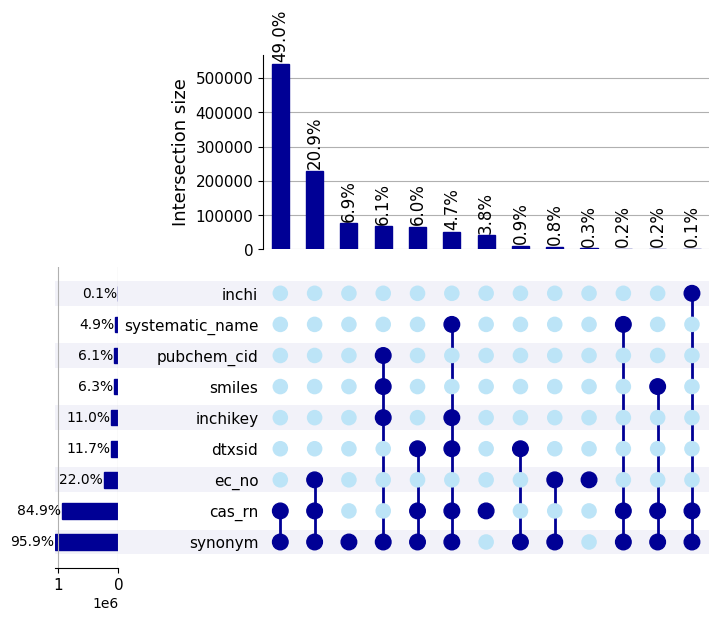

In [15]:
# -------------------------
# Input cleanup
# -------------------------
df = (
    curation_data[
        ["ticket_name", "record_id", "identifier_type", "identifier_value"]
    ]
    .dropna(subset=["record_id", "identifier_type"])
    .drop_duplicates(subset=["record_id", "identifier_type"])
)

# Optional: keep only the most common identifier types
# This prevents unreadable UpSet plots if there are many rare identifier categories.
top_types_n = 10

top_types = (
    df["identifier_type"]
    .value_counts()
    .head(top_types_n)
    .index
)

df_upset = df[df["identifier_type"].isin(top_types)].copy()

# -------------------------
# Convert records to memberships
# -------------------------
memberships = (
    df_upset
    .groupby("record_id")["identifier_type"]
    .apply(lambda x: sorted(set(x)))
)

# Convert to UpSet-compatible Series
upset_data = from_memberships(memberships)

# -------------------------
# Plot
# -------------------------
fig = plt.figure(figsize=(12, 7), constrained_layout=True)

upset = UpSet(
    upset_data,
    subset_size="count",
    show_percentages="{:.1%}",
    sort_by="cardinality",
    sort_categories_by="cardinality",
    min_subset_size=1000,
    facecolor="#000095",
    other_dots_color="#BCE4F7",
    with_lines=True,
)

axes = upset.plot(fig=fig)

# Increase text sizes
for ax in fig.axes:

    ax.title.set_fontsize(14)

    ax.xaxis.label.set_fontsize(13)
    ax.yaxis.label.set_fontsize(13)

    ax.tick_params(axis="both", labelsize=11)

    for text in ax.texts:
        text.set_fontsize(10)

for txt in axes["intersections"].texts:
    txt.set_rotation(90)
    txt.set_ha("center")
    txt.set_va("bottom")
    txt.set_fontsize(12)

# Important
fig.savefig(
    "./figures/upset_curation.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.1,
)

plt.show()

In [16]:
ids = curated_data['cichem_id'].drop_duplicates().to_list()

identifier_data = pd.read_parquet(r"parquets/identifier_data.parquet")

C:\Users\CharestNate\AppData\Local\Temp\ipykernel_17824\319966118.py:111: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.savefig(
C:\Users\CharestNate\OneDrive - ULRI-ULSE\Documents\Projects\proj-4-chemical-inventory-mapping\writing\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


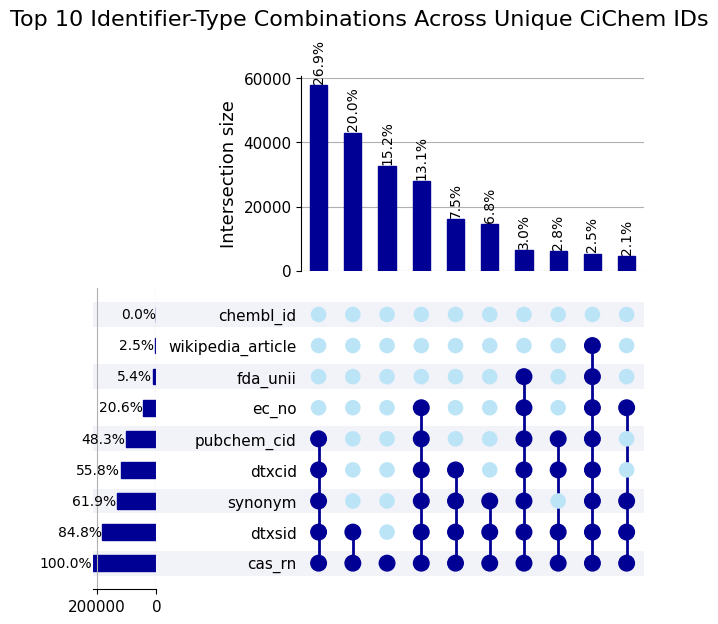

In [17]:
# If needed:
# %pip install upsetplot

# ------------------------------------------------------------
# 1) Build presence/absence matrix:
#    one row per cichem_id, one Boolean column per identifier type
# ------------------------------------------------------------

identifier_presence = (
    identifier_data[["cichem_id", "identifier_type"]]
    .dropna(subset=["cichem_id", "identifier_type"])
    .assign(
        cichem_id=lambda df: df["cichem_id"].astype("string").str.strip(),
        identifier_type=lambda df: df["identifier_type"].astype("string").str.strip(),
    )
    .loc[lambda df: df["cichem_id"].ne("") & df["identifier_type"].ne("")]
    .drop_duplicates(["cichem_id", "identifier_type"])
    .assign(present=True)
    .pivot(
        index="cichem_id",
        columns="identifier_type",
        values="present",
    )
    .fillna(False)
    .astype(bool)
)

# Remove any identifier-type columns that are not present for any chemical
identifier_presence = identifier_presence.loc[
    :,
    identifier_presence.any(axis=0)
]

if identifier_presence.empty:
    raise ValueError(
        "No valid cichem_id / identifier_type combinations were found."
    )

# ------------------------------------------------------------
# 2) Count unique cichem_ids belonging to each exact combination
# ------------------------------------------------------------

combination_counts = (
    identifier_presence
    .value_counts(sort=False)
    .rename("n_cichem_ids")
)

# ------------------------------------------------------------
# 3) Generate UpSet plot
# ------------------------------------------------------------

TOP_N_COMBINATIONS = 10

top_combinations = (
    combination_counts
    .nlargest(TOP_N_COMBINATIONS)
)

fig = plt.figure(
    figsize=(10, 6),
    constrained_layout=True,
)

upset = UpSet(
    top_combinations,
    subset_size="sum",
    show_percentages="{:.1%}",
    sort_by="cardinality",
    sort_categories_by="cardinality",
    facecolor="#000095",
    other_dots_color="#BCE4F7",
    with_lines=True,
)

axes = upset.plot(fig=fig)

# ------------------------------------------------------------
# Styling
# ------------------------------------------------------------

for ax in fig.axes:

    ax.tick_params(
        axis="both",
        labelsize=11,
    )

    if ax.get_ylabel() == "Intersection size":
        ax.yaxis.label.set_size(13)

        for txt in ax.texts:
            txt.set_fontsize(11)
            txt.set_rotation(90)

    if ax.get_xlabel() == "Set size":
        ax.xaxis.label.set_size(13)

    for text in ax.texts:
        text.set_fontsize(10)

fig.suptitle(
    "Top 10 Identifier-Type Combinations Across Unique CiChem IDs",
    fontsize=16,
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

fig.savefig(
    "./figures/post-mapping-identifiers.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05,
    facecolor="white",
)

plt.show()


In [18]:
keyword_types = ['biological_material', 'descriptive', 'nonbiological_complex_origin', 'process_related', 'substance_related']
keywords = {}

for i in keyword_types:
    keywords[i] = [i.replace(" ", "") for i in list(pd.read_csv(r"./keywords/{}.csv".format(i)).columns)]

In [19]:
curated_data[['primary_name']].drop_duplicates().dropna()

,primary_name
20,Guanidine monohydrochloride
28,Dexamethasone
56,Cortisone acetate
68,Phenobarbital
148,Hydrocortisone
...,...
7379533,Mono(carboxyisooctyl) phthalate
7379930,Bisphenol A disulfate
7380197,Mono(3-hydroxy-n-butyl) phthalate
7380270,7-Carboxy-(mono-methyl-heptyl) phthalate


In [20]:
# ---------------------------
# build keyword -> category map
# ---------------------------

keyword_map = {
    word: category
    for category, words in keywords.items()
    for word in words
}

# Convert categorical values to strings before filling nulls
names = (
    curated_data["primary_name"]
    .astype("string")
    .drop_duplicates()
    .fillna("")
    .str.lower()
)

# ---------------------------
# ordinary keyword hits
# ---------------------------

keyword_hits = pd.DataFrame(
    {
        kw: names.str.contains(
            re.escape(kw.lower()),
            regex=True,
            na=False,
        ).astype("int8")
        for kw in keyword_map
    },
    index=names.index,
)

carbon_pattern = (
    r"\(or \d+\)"
    r"|c=?\d{1,2}(?:\d{1,2})?-\d{1,2}(?:\d{1,2})?"
)

keyword_hits["carbon_chain"] = (
    names.str.contains(
        carbon_pattern,
        regex=True,
        case=False,
        na=False,
    )
    .astype("int8")
)

keyword_hits["ite"] = (
    names.str.contains(
        "ite",
        case=False,
        regex=False,
        na=False,
    )
    & ~names.str.contains(
        r"phosphite|phosphinite|phosphoramidite",
        case=False,
        regex=True,
        na=False,
    )
).astype("int8")

keyword_hits

,extractives,ext.,DNA,GenBank,protein,peptide,blood,hemoglobin,hemoglobins,antiserums,...,bases,ethers,imines,epoxides,trialkyls,chlorides,silicones,Lipopolysaccharides,carbon_chain,ite
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
28,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
56,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
68,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7379533,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7379930,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7380197,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7380270,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Removing 'poly' from 28,319 records where 'polymer' is also present.
Total non-empty keyword combinations: 115
Combinations after filtering: 8
Minimum plotted intersection size: 1,468


,acids,carbon_chain,fat,oil,poly,polymer,products,reaction,record_count
0,False,False,False,False,False,True,False,False,21507
1,False,True,False,False,False,False,False,False,4849
2,False,False,False,False,True,False,False,False,3401
3,False,False,False,False,False,False,True,True,3280
4,False,False,False,True,False,True,False,False,2228
5,False,False,True,False,False,False,False,False,2179
6,False,False,False,True,False,False,False,False,2109
7,True,False,True,True,False,True,False,False,1468


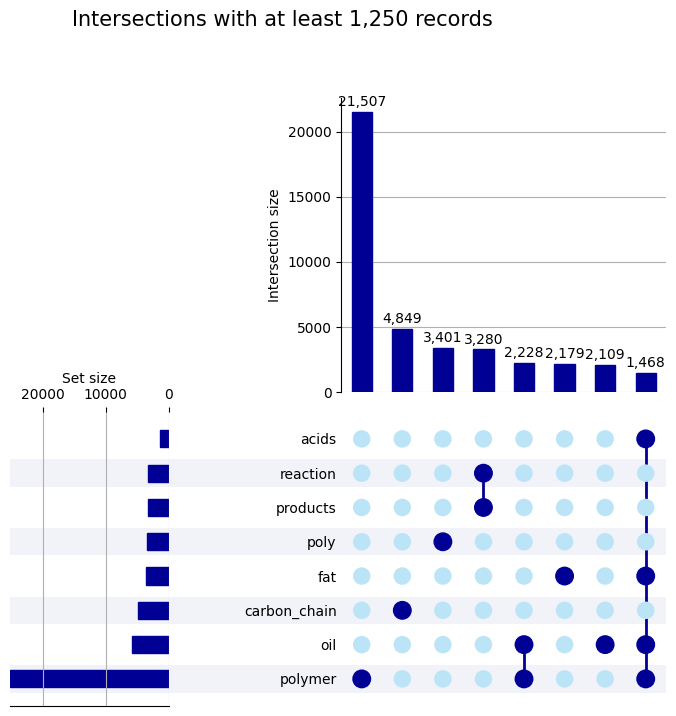

Saved figure to: ./figures/upset_ROCKS_keywords.png


In [21]:
# ------------------------------------------------------------
# Copy and clean keyword matrix
# ------------------------------------------------------------

keyword_hits_clean = keyword_hits.loc[
    :,
    keyword_hits.sum() >= 5000
].copy()

# ------------------------------------------------------------
# Remove "poly" whenever "polymer" is present
# ------------------------------------------------------------

if {"poly", "polymer"}.issubset(keyword_hits_clean.columns):
    poly_present = keyword_hits_clean["poly"].fillna(0).ne(0)
    polymer_present = keyword_hits_clean["polymer"].fillna(0).ne(0)

    overlap_mask = poly_present & polymer_present

    print(
        f"Removing 'poly' from {overlap_mask.sum():,} records "
        "where 'polymer' is also present."
    )

    # Preserve the int8 dtype
    keyword_hits_clean.loc[overlap_mask, "poly"] = 0

# ------------------------------------------------------------
# Build memberships
# ------------------------------------------------------------

memberships = keyword_hits_clean.apply(
    lambda row: tuple(row.index[row.astype(bool)].tolist()),
    axis=1,
)

# Remove rows with no remaining keywords
memberships = memberships[memberships.map(len) > 0]

# ------------------------------------------------------------
# Explicit intersection counts
# ------------------------------------------------------------

intersection_counts = (
    memberships
    .value_counts()
    .sort_values(ascending=False)
)

# ------------------------------------------------------------
# Convert to UpSet format
# ------------------------------------------------------------

all_keywords = sorted(
    {
        keyword
        for combo in intersection_counts.index
        for keyword in combo
    }
)

bool_index = pd.MultiIndex.from_tuples(
    [
        tuple(keyword in combo for keyword in all_keywords)
        for combo in intersection_counts.index
    ],
    names=all_keywords,
)

upset_data = pd.Series(
    intersection_counts.values,
    index=bool_index,
    name="count",
)

# ------------------------------------------------------------
# Hard-filter intersections
# ------------------------------------------------------------

min_intersection_size = 1250
max_intersections = 25

upset_data_filtered = (
    upset_data[upset_data >= min_intersection_size]
    .sort_values(ascending=False)
    .head(max_intersections)
)

print(f"Total non-empty keyword combinations: {len(upset_data):,}")
print(f"Combinations after filtering: {len(upset_data_filtered):,}")
print(
    f"Minimum plotted intersection size: "
    f"{upset_data_filtered.min():,}"
)

# ------------------------------------------------------------
# Diagnostic table
# ------------------------------------------------------------

display(
    upset_data_filtered
    .reset_index(name="record_count")
    .sort_values("record_count", ascending=False)
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig = plt.figure(figsize=(16, 8))

upset = UpSet(
    upset_data_filtered,
    subset_size="sum",
    sort_by="cardinality",
    sort_categories_by="cardinality",
    show_counts="{:,.0f}",
    facecolor="#000095",
    other_dots_color="#BCE4F7",
    with_lines=True,
    element_size=36,
    totals_plot_elements=4,
    intersection_plot_elements=8,
)

axes = upset.plot(fig=fig)

# Smaller count labels
for ax in axes.values():
    for txt in ax.texts:
        txt.set_fontsize(10)

# ------------------------------------------------------------
# Clean totals axis
# ------------------------------------------------------------

totals_ax = axes["totals"]

totals_ax.xaxis.set_ticks_position("top")
totals_ax.xaxis.set_label_position("top")
totals_ax.tick_params(
    axis="x",
    labeltop=True,
    labelbottom=False,
)

totals_ax.set_xlabel("Set size")

# Remove labels from totals bars
for txt in totals_ax.texts:
    txt.remove()

# ------------------------------------------------------------
# Final formatting
# ------------------------------------------------------------

axes["intersections"].set_ylabel("Intersection size")
axes["matrix"].set_xlabel("Keyword combination")

fig.suptitle(
    f"Intersections with at least {min_intersection_size:,} records",
    y=0.99,
    fontsize=15,
)

# Do not use fig.tight_layout() here; it is unreliable with UpSet's
# internally constructed GridSpec and can crop labels or the title.

# Explicitly reserve exterior space
fig.subplots_adjust(
    left=0.16,
    right=0.98,
    bottom=0.12,
    top=0.88,
)

# Force Matplotlib to finish positioning all artists before calculating
# the output bounding box.
fig.canvas.draw()

output_path = r"./figures/upset_ROCKS_keywords.png"

#fig.tight_layout()
fig.savefig(
    output_path,
    dpi=300,
    format="png",
    bbox_inches="tight",
    pad_inches=0.35,
    facecolor="white",
    edgecolor="none",
)

plt.show()

print(f"Saved figure to: {output_path}")

In [22]:
import plotly.io as pio
pio.renderers.default = "notebook"     # classic Jupyter
# or:
pio.renderers.default = "notebook_connected"
# or:
pio.renderers.default = "jupyterlab"
# or (safe fallback):
pio.renderers.default = "browser"


In [57]:
curation_data.head(3)

,ticket_name,record_id,match_id,identifier_type,identifier_value,primary_name,cichem_id,average_mass,inchikey
0,ROCKS_2026_I16_vietnam-in-commerce,8220906,28025972.0,cas_rn,50-00-0,Formaldehyde,CICHEM000206375,30.025999,WSFSSNUMVMOOMR-UHFFFAOYSA-N
1,ROCKS_2026_I16_vietnam-in-commerce,8220906,27988367.0,cas_rn,50-00-0,Formaldehyde,CICHEM000206375,30.025999,WSFSSNUMVMOOMR-UHFFFAOYSA-N
2,ROCKS_2026_I16_vietnam-in-commerce,8220906,27960405.0,cas_rn,50-00-0,Formaldehyde,CICHEM000206375,30.025999,WSFSSNUMVMOOMR-UHFFFAOYSA-N


In [63]:
curated_data['ticket_name'].dropna().drop_duplicates()

0          ROCKS_2026_I16_vietnam-in-commerce
88174      ROCKS_2026_I4a_chile-planilla-2024
142901      ROCKS_2026_I11a_philippines-piccs
159270                ROCKS_2026_I15a_us-tsca
306547                ROCKS_2026_C4_swiss-rpc
                          ...                
6815683          ROCKS_2026_F9_FOODCONTACTSDB
7026912            ROCKS_2026_I18_ANITMICROB2
7318060            ROCKS_2026_A22_SWISSPEST19
7331987                ROCKS_2026_E16_mmdbenv
7372826                ROCKS_2026_B19_mmdbbio
Name: ticket_name, Length: 129, dtype: category
Categories (129, str): ['ROCKS_2026_A10_eu-pesticides', 'ROCKS_2026_A11_eu-fertilizer-ligands', 'ROCKS_2026_A12_pmra-formulants', 'ROCKS_2026_A13_icama-actives', ..., 'ROCKS_2026_I7c_japan-notif', 'ROCKS_2026_I7d_japan-pacs', 'ROCKS_2026_I8_malaysia-dosh', 'ROCKS_2026_I9_mexico-insq']

In [64]:
# ------------------------------------------------------------
# 0) Ensure domain exists from ticket_name
# ------------------------------------------------------------

domain_map = {
    "I": "Industrial",
    "A": "Agriculture",
    "F": "Food",
    "E": "Environmental Monitoring",
    "B": "Biomonitoring",
    "C": "Consumer Products",
    "D": "Pharmaceuticals",
}

if "domain" not in curation_data.columns:
    curated_data["domain"] = (
        curated_data["ticket_name"]
        .astype("string")
        .str.extract(r"^ROCKS_\d{4}_([IAFEBCD])\d+[a-z]?_", expand=False)
        .map(domain_map)
    )

# ------------------------------------------------------------
# 1) Get cichem_id from existing column OR identifier rows
# ------------------------------------------------------------

df = curated_data.copy()

if "cichem_id" in df.columns:
    df["cichem_id"] = df["cichem_id"]
elif {"identifier_type", "identifier_value"}.issubset(df.columns):
    cichem_mask = (
        df["identifier_type"]
        .astype("string")
        .str.lower()
        .str.strip()
        .isin(["cichem_id", "cichemid", "ci_chem_id"])
    )

    df = df.loc[cichem_mask].copy()
    df["cichem_id"] = df["identifier_value"]
else:
    raise ValueError(
        "Expected either a 'cichem_id' column or both "
        "'identifier_type' and 'identifier_value' columns."
    )

# ------------------------------------------------------------
# 2) Clean cichem_id and domain values
# ------------------------------------------------------------

df["cichem_id"] = (
    df["cichem_id"]
    .astype("string")
    .str.strip()
)

df.loc[
    df["cichem_id"].isin(["", "nan", "None", "NA", "NaN"]),
    "cichem_id"
] = pd.NA

df["domain"] = (
    df["domain"]
    .astype("string")
    .str.strip()
)

df.loc[
    df["domain"].isin(["", "nan", "None", "NA", "NaN"]),
    "domain"
] = pd.NA

# ------------------------------------------------------------
# 3) Build long-form domain assignment table
# ------------------------------------------------------------

keep_cols = ["cichem_id", "domain"]

optional_cols = [
    "ticket_name",
    "record_id",
    "identifier_type",
    "identifier_value",
]

keep_cols += [c for c in optional_cols if c in df.columns]

use_domain_df = (
    df[keep_cols]
    .dropna(subset=["cichem_id", "domain"])
    .drop_duplicates()
    .rename(columns={"domain": "use_domain_label"})
)

# ------------------------------------------------------------
# 4) Build pivot: one row per cichem_id, domains collapsed
# ------------------------------------------------------------

use_domain_pivot = (
    use_domain_df
    .groupby("cichem_id", as_index=True)["use_domain_label"]
    .agg(lambda x: ",".join(sorted(set(x.dropna()))))
    .to_frame(name="use_domain_labels")
    .sort_index()
)

# ------------------------------------------------------------
# 5) Basic sanity checks
# ------------------------------------------------------------

print(f"Input rows:              {len(curation_data):,}")
print(f"Rows with cichem/domain: {len(use_domain_df):,}")
print(f"Unique cichem_ids:       {use_domain_pivot.shape,}")

print("\nDomain counts by unique cichem_id membership:")
display(
    use_domain_df
    .drop_duplicates(["cichem_id", "use_domain_label"])
    ["use_domain_label"]
    .value_counts()
    .rename_axis("domain")
    .to_frame("n_unique_cichem_ids")
)

display(use_domain_pivot.head())

Input rows:              7,380,370
Rows with cichem/domain: 2,296,844
Unique cichem_ids:       ((238602, 1),)

Domain counts by unique cichem_id membership:


,n_unique_cichem_ids
domain,
Industrial,209700
Consumer Products,36259
Biomonitoring,28476
Food,17782
Agriculture,10769
Environmental Monitoring,3263
Pharmaceuticals,3036


,use_domain_labels
cichem_id,
CICHEM000200014,"Biomonitoring,Consumer Products"
CICHEM000200048,"Biomonitoring,Consumer Products,Industrial"
CICHEM000200055,"Biomonitoring,Consumer Products,Environmental ..."
CICHEM000200063,"Agriculture,Biomonitoring,Consumer Products,En..."
CICHEM000200071,"Biomonitoring,Industrial,Pharmaceuticals"


In [66]:
use_domain_pivot

,use_domain_labels
cichem_id,
CICHEM000200014,"Biomonitoring,Consumer Products"
CICHEM000200048,"Biomonitoring,Consumer Products,Industrial"
CICHEM000200055,"Biomonitoring,Consumer Products,Environmental ..."
CICHEM000200063,"Agriculture,Biomonitoring,Consumer Products,En..."
CICHEM000200071,"Biomonitoring,Industrial,Pharmaceuticals"
...,...
CICHEM014286793,Industrial
CICHEM014286801,Industrial
CICHEM014286819,Industrial


In [67]:
def filter_by_domain(df, domain):
    """
    Return rows whose use_domain_labels contain the specified domain.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing a 'use_domain_labels' column.
    domain : str
        e.g. 'Pharmaceuticals'

    Returns
    -------
    pd.DataFrame
    """
    mask = (
        df["use_domain_labels"]
        .fillna("")
        .str.split(",")
        .apply(lambda x: domain in x)
    )

    return df.loc[mask].copy()

Chemicals with at least one use-domain label: 238,602


domain_memberships
INDUSTRIAL                  209700
CONSUMER PRODUCTS            36259
BIOMONITORING                28476
FOOD                         17782
AGRICULTURE                  10769
ENVIRONMENTAL MONITORING      3263
PHARMACEUTICALS               3036
Name: count, dtype: int64

No pipe-combined domain labels remain.


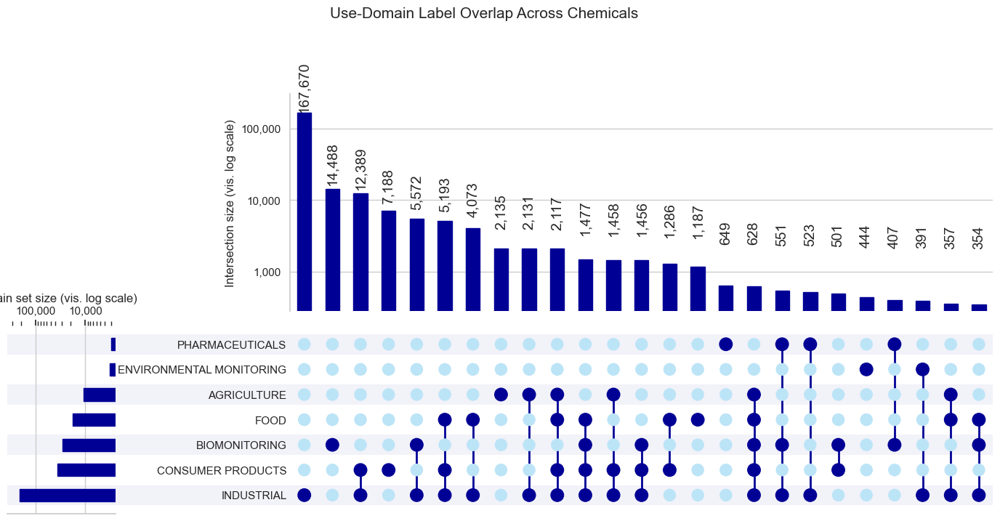

In [68]:

# ------------------------------------------------------------
# Input
# ------------------------------------------------------------

use_domains_df = use_domain_pivot.copy()

# If cichem_id is the index, move it into a real column.
if "cichem_id" not in use_domains_df.columns:
    use_domains_df = use_domains_df.reset_index()

    if "cichem_id" not in use_domains_df.columns:
        first_col = use_domains_df.columns[0]
        use_domains_df = use_domains_df.rename(columns={first_col: "cichem_id"})

df_domains = (
    use_domains_df[["cichem_id", "use_domain_labels"]]
    .dropna(subset=["cichem_id", "use_domain_labels"])
    .copy()
)

# ------------------------------------------------------------
# Parse use-domain labels
# Splits on commas OR pipes, so "AGRICULTURAL|FOOD" becomes:
# ["AGRICULTURAL", "FOOD"]
# ------------------------------------------------------------

def parse_domain_labels(x):
    if pd.isna(x):
        return []

    labels = re.split(r"[,|]", str(x))

    labels = [
        label.strip().upper()
        for label in labels
        if label.strip()
    ]

    return sorted(set(labels))


df_domains["domain_memberships"] = (
    df_domains["use_domain_labels"]
    .apply(parse_domain_labels)
)

df_domains = df_domains[df_domains["domain_memberships"].map(len) > 0].copy()

print(
    f"Chemicals with at least one use-domain label: "
    f"{df_domains['cichem_id'].nunique():,}"
)

# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

domain_counts = (
    df_domains["domain_memberships"]
    .explode()
    .value_counts()
)

display(domain_counts)

# Confirm no accidental pipe labels remains
bad_combined_labels = (
    df_domains["domain_memberships"]
    .explode()
    .loc[lambda s: s.astype(str).str.contains(r"\|", regex=True, na=False)]
    .value_counts()
)

if len(bad_combined_labels):
    print("WARNING: Combined pipe labels still present:")
    display(bad_combined_labels)
else:
    print("No pipe-combined domain labels remain.")

# ------------------------------------------------------------
# Build UpSet-compatible data
# ------------------------------------------------------------

upset_data = from_memberships(
    df_domains["domain_memberships"],
    data=df_domains["cichem_id"].values,
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig = plt.figure(figsize=(15, 8))

upset = UpSet(
    upset_data,
    subset_size="count",
    sort_by="cardinality",
    sort_categories_by="cardinality",
    max_subset_rank=25,
    show_counts="{:,.0f}",
    facecolor="#000095",
    other_dots_color="#BCE4F7",
    with_lines=True,
    element_size=36,
    totals_plot_elements=4,
    intersection_plot_elements=8,
)

axes = upset.plot(fig=fig)

# ------------------------------------------------------------
# Safe log scaling
# ------------------------------------------------------------

comma_formatter = FuncFormatter(lambda x, pos: f"{x:,.0f}" if x >= 1 else "")

# Top intersection-size bars use y-axis
intersection_values = upset.intersections.astype(float)
intersection_values = intersection_values[intersection_values > 0]

if not intersection_values.empty:
    ymin = max(1, intersection_values.min() * 0.8)
    ymax = intersection_values.max() * 1.8

    axes["intersections"].set_yscale("log")
    axes["intersections"].set_ylim(ymin, ymax)
    axes["intersections"].yaxis.set_major_formatter(comma_formatter)
    axes["intersections"].set_ylabel("Intersection size (vis. log scale)")

# Left set-size bars use x-axis
if axes["totals"] is not None:
    totals_values = upset.totals.astype(float)
    totals_values = totals_values[totals_values > 0]

    if not totals_values.empty:
        xmin = max(1, totals_values.min() * 0.8)
        xmax = totals_values.max() * 1.8

        axes["totals"].set_xscale("log")
        axes["totals"].set_xlim(xmax, xmin)

        axes["totals"].xaxis.set_major_formatter(comma_formatter)
        axes["totals"].xaxis.set_ticks_position("top")
        axes["totals"].xaxis.set_label_position("top")
        axes["totals"].tick_params(axis="x", labeltop=True, labelbottom=False)
        axes["totals"].set_xlabel("Main set size (vis. log scale)")

# ------------------------------------------------------------
# Cleanup
# ------------------------------------------------------------

for txt in axes["intersections"].texts:
    txt.set_fontsize(10)
    txt.set_rotation(90)
    txt.set_ha("center")
    txt.set_va("bottom")
    txt.set_fontsize(14)

if axes["totals"] is not None:
    for txt in axes["totals"].texts:
        txt.remove()

axes["matrix"].set_xlabel("Use-domain combination")

fig.suptitle(
    "Use-Domain Label Overlap Across Chemicals",
    y=1.04,
    fontsize=15,
)

plt.savefig(r"./figures/upset_ROCKS_usedomain.png")
plt.show()

In [26]:

chemicals = pd.read_parquet(r"./parquets/chemicals_data.parquet")

Loaded cached fingerprints + DensMAP: (167950, 8)


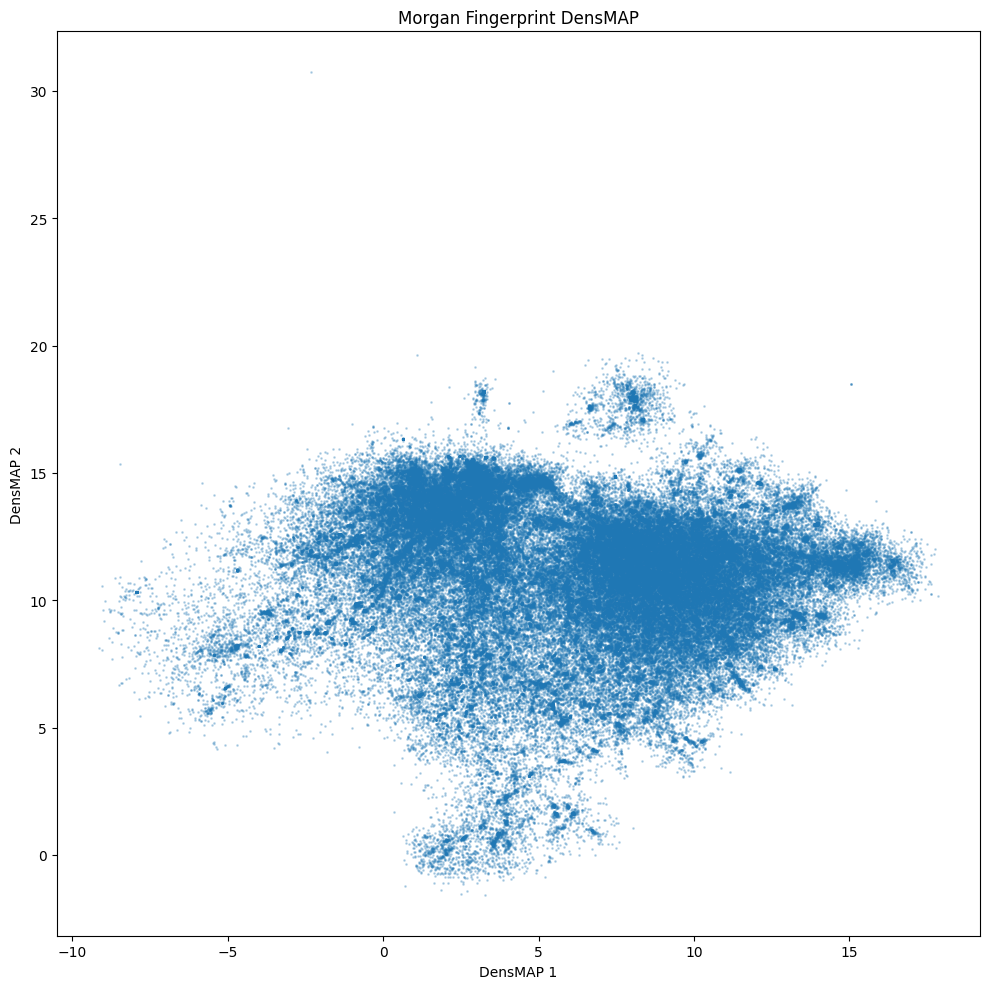

,cichem,cicomp,primary_name,fp,densmap_1,densmap_2,densmap_r_orig,densmap_r_emb
0,CICHEM000751677,CICOMP000361246,"2,4-Dichloro-6-benzylphenol",0000000000000000000000000000000000000000000000...,9.553433,10.370105,-1.851966,-2.936195
1,CICHEM000516914,CICOMP000302463,C.I. Pigment Yellow 73,0100000000000000001000000000000000000000000000...,13.908660,12.956450,-2.572332,-3.124136
2,CICHEM001878792,CICOMP001103704,"4-Methyl-2,3-dihydrofuran",0000000000000000000000000000000000000000000000...,2.960596,6.992408,-1.069977,-1.984400
3,CICHEM000350165,CICOMP008206971,Zinc oxide,0000000000000000000000000000000000000000000000...,-5.360163,7.607424,-1.637890,-1.794851
4,CICHEM001477314,CICOMP000702225,Diethyl acetonylphosphonate,0000000000000000000000000000000000000000000000...,0.701528,11.723622,-1.904974,-2.759942


In [27]:
# --------------------------------------------------
# Configuration
# --------------------------------------------------

FP_PATH = "./parquets/chemical_fingerprint_densmap.parquet"

# Input dataframe expected:
# chemicals columns include:
#   cichem
#   cicomp
#   primary_name
#   fp
#
# where fp is a fixed-length bitstring like:
#   "000010001000..."

required_cols = ["cichem", "cicomp", "primary_name"]

missing = [c for c in required_cols if c not in chemicals.columns]
if missing:
    raise ValueError(f"Missing required columns in chemicals: {missing}")

# --------------------------------------------------
# FAST PATH: reuse cached DensMAP coordinates
# --------------------------------------------------

if os.path.exists(FP_PATH):
    fingerprints_df = pd.read_parquet(r"./parquets/chemical_fingerprint_densmap.parquet")
    print(f"Loaded cached fingerprints + DensMAP: {fingerprints_df.shape}")

else:
    print(f"No fingerprint file found. Chemicals shape: {chemicals.shape}")
    # --------------------------------------------------
    # SLOW PATH: parse existing fingerprint bitstrings
    # --------------------------------------------------

    fingerprints_df = (
        chemicals[required_cols]
        .dropna(subset=["fp"])
        .copy()
    )

    fingerprints_df["fp"] = fingerprints_df["fp"].astype(str).str.strip()

    # Validate fingerprint lengths
    fp_lengths = fingerprints_df["fp"].str.len()
    length_counts = fp_lengths.value_counts().sort_index()

    print("Fingerprint length distribution:")
    print(length_counts)

    if length_counts.shape[0] != 1:
        modal_len = length_counts.idxmax()
        print(f"\nMultiple fingerprint lengths detected. Keeping modal length: {modal_len}")

        fingerprints_df = fingerprints_df[fp_lengths.eq(modal_len)].copy()
        fingerprints_df["fp"] = fingerprints_df["fp"].astype(str).str.strip()

    fp_len = fingerprints_df["fp"].str.len().iloc[0]
    n = fingerprints_df.shape[0]

    print(f"\nUsing {n:,} fingerprints of length {fp_len:,}")

    # Validate that fingerprints are only 0/1 characters
    bad_fp_mask = ~fingerprints_df["fp"].str.fullmatch(r"[01]+")
    n_bad = int(bad_fp_mask.sum())

    if n_bad:
        print(f"Dropping {n_bad:,} rows with non-binary fingerprint strings")
        fingerprints_df = fingerprints_df.loc[~bad_fp_mask].copy()
        n = fingerprints_df.shape[0]

    # --------------------------------------------------
    # Convert bitstrings to numeric matrix
    # --------------------------------------------------
    # Efficient path:
    # concatenate strings, convert ASCII chars to uint8,
    # reshape to n x fp_len, then subtract ord("0").
    # Result is dense binary matrix.

    fp_blob = "".join(fingerprints_df["fp"].to_numpy())

    X_mat = (
        np.frombuffer(fp_blob.encode("ascii"), dtype=np.uint8)
        .reshape(n, fp_len)
        - ord("0")
    ).astype(np.float32)

    print(f"X_mat shape: {X_mat.shape}")
    print(f"X_mat dtype: {X_mat.dtype}")

    # --------------------------------------------------
    # Fit DensMAP
    # --------------------------------------------------

    n_neighbors = max(2, int(X_mat.shape[0] * 0.0025))
    print(f"n_neighbors = {n_neighbors:,}")

    umap_model = umap.UMAP(
        n_components=2,
        n_neighbors=n_neighbors,
        metric="cosine",
        init="random",
        densmap=True,
        output_dens=True,
        random_state=42,
        verbose=True,
        n_jobs=-1,
    )

    X_umap, r_orig, r_emb = umap_model.fit_transform(X_mat)

    fingerprints_df["densmap_1"] = X_umap[:, 0]
    fingerprints_df["densmap_2"] = X_umap[:, 1]
    fingerprints_df["densmap_r_orig"] = r_orig
    fingerprints_df["densmap_r_emb"] = r_emb

    # Optional: do not cache massive raw fingerprints if you only need coords later.
    # If you want to keep fp in the cache, leave this as-is.
    fingerprints_df.to_csv(FP_PATH, index=False)

    print(f"Saved fingerprints + DensMAP to {FP_PATH}")

# --------------------------------------------------
# Quick visualization
# --------------------------------------------------

plt.figure(figsize=(10, 10))

plt.scatter(
    fingerprints_df["densmap_1"],
    fingerprints_df["densmap_2"],
    s=1,
    alpha=0.25,
)

plt.xlabel("DensMAP 1")
plt.ylabel("DensMAP 2")
plt.title("Morgan Fingerprint DensMAP")

plt.tight_layout()
plt.show()

fingerprints_df.head()

In [28]:
len(structured_cichems)

166630

In [29]:
fingerprints_df.loc[~fingerprints_df['cichem'].isin(structured_cichems)]

,cichem,cicomp,primary_name,fp,densmap_1,densmap_2,densmap_r_orig,densmap_r_emb
353,CICHEM000252189,CICOMP017655994,Polyoxyethylene dodecyl mono ether,0000000000000100000000000000000000000000000000...,0.999206,13.680930,-4.119814,-4.432384
391,CICHEM000418541,CICOMP012851606,Dichlorobenzene,0000000000000000000000000000000000000000000000...,9.570787,10.434061,-1.502570,-3.126251
433,CICHEM000259408,CICOMP018445163,Polyvinyl chloride,0100000000000000000000000000000000000000000000...,-1.564972,10.983672,-1.067098,-2.304428
986,CICHEM000408039,CICOMP017651134,Nylon 12,0000000000000000000000000000000000000000010000...,1.672014,13.692716,-1.771106,-3.060584
1099,CICHEM000420448,CICOMP012851663,Hexanol,0000000000000000000000000000000000000000000000...,1.031226,13.725092,-1.750340,-3.000155
...,...,...,...,...,...,...,...,...
167648,CICHEM014286231,CICOMP018934851,"2-Propenoic acid, 2-(hydroxymethyl)-2-[[(1-oxo...",0000000100000000000000000000000000000000000000...,4.098269,14.046288,-2.044556,-2.782834
167650,CICHEM014286421,CICOMP018934877,"Poly(oxy-1,2-ethanediyl), α-(2,6,8-trimethylno...",0100000000000100000000000000000000000000000000...,1.041217,13.778482,-1.959454,-3.403755
167652,CICHEM014286629,CICOMP018934893,"2-Propenoic acid, 2-methyl-, cyclohexyl ester,...",0010000000000100000000000000000000000000000000...,5.233797,14.437799,-2.203820,-3.189114
167711,CICHEM008726192,CICOMP017780792,Methoxy polyethylene glycol 550,0000000000000100000000000000000000000000000000...,1.332902,13.062985,-1.714375,-3.228718


In [30]:
import pandas as pd

# ------------------------------------------------------------
# Normalize IDs in both source dataframes
# ------------------------------------------------------------

curation_ids = (
    curation_data["cichem_id"]
    .astype("string")
    .str.strip()
    .replace(["", "nan", "None", "NA", "NaN"], pd.NA)
    .dropna()
    .drop_duplicates()
)

curated_id_column = (
    "cichem_id"
    if "cichem_id" in curated_data.columns
    else "cichemid"
)

curated_ids = (
    curated_data[curated_id_column]
    .astype("string")
    .str.strip()
    .replace(["", "nan", "None", "NA", "NaN"], pd.NA)
    .dropna()
    .drop_duplicates()
)

use_domain_ids = (
    use_domain_df["cichem_id"]
    .astype("string")
    .str.strip()
    .replace(["", "nan", "None", "NA", "NaN"], pd.NA)
    .dropna()
    .drop_duplicates()
)

# ------------------------------------------------------------
# Compare populations
# ------------------------------------------------------------

curation_id_set = set(curation_ids)
curated_id_set = set(curated_ids)
use_domain_id_set = set(use_domain_ids)

print(f"Unique IDs in curation_data: {len(curation_id_set):,}")
print(f"Unique IDs in curated_data:  {len(curated_id_set):,}")
print(f"Unique IDs in use_domain_df: {len(use_domain_id_set):,}")

print(
    "\nIn curation_data but absent from curated_data: "
    f"{len(curation_id_set - curated_id_set):,}"
)

print(
    "In curated_data but absent from use_domain_df: "
    f"{len(curated_id_set - use_domain_id_set):,}"
)

print(
    "In curation_data but absent from use_domain_df: "
    f"{len(curation_id_set - use_domain_id_set):,}"
)

# ------------------------------------------------------------
# Diagnose why curated_data rows are removed
# ------------------------------------------------------------

diagnostic_df = curated_data.copy()

if "cichem_id" not in diagnostic_df.columns:
    diagnostic_df["cichem_id"] = diagnostic_df[curated_id_column]

diagnostic_df["cichem_id"] = (
    diagnostic_df["cichem_id"]
    .astype("string")
    .str.strip()
    .replace(["", "nan", "None", "NA", "NaN"], pd.NA)
)

diagnostic_df["domain"] = (
    diagnostic_df["domain"]
    .astype("string")
    .str.strip()
    .replace(["", "nan", "None", "NA", "NaN"], pd.NA)
)

print("\nRow-level missingness:")
print(f"Rows with missing cichem_id: {diagnostic_df['cichem_id'].isna().sum():,}")
print(f"Rows with missing domain:    {diagnostic_df['domain'].isna().sum():,}")

ids_without_domain = (
    diagnostic_df.loc[
        diagnostic_df["cichem_id"].notna()
        & diagnostic_df["domain"].isna(),
        "cichem_id",
    ]
    .drop_duplicates()
)

print(
    "Unique chemicals present in curated_data but having no domain: "
    f"{len(ids_without_domain):,}"
)

# ------------------------------------------------------------
# Inspect missing IDs
# ------------------------------------------------------------

missing_from_use_domain = sorted(
    curation_id_set - use_domain_id_set
)

missing_domain_diagnostic = pd.DataFrame(
    {"cichem_id": missing_from_use_domain}
).merge(
    diagnostic_df[
        ["cichem_id", "ticket_name", "domain"]
    ].drop_duplicates(),
    on="cichem_id",
    how="left",
)

#display(missing_domain_diagnostic.head(50))

Unique IDs in curation_data: 249,112
Unique IDs in curated_data:  238,602
Unique IDs in use_domain_df: 172,354

In curation_data but absent from curated_data: 10,511
In curated_data but absent from use_domain_df: 66,248
In curation_data but absent from use_domain_df: 76,759

Row-level missingness:
Rows with missing cichem_id: 1,249,174
Rows with missing domain:    2,876,051
Unique chemicals present in curated_data but having no domain: 172,329


In [31]:
import os
from urllib.parse import quote
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
import pandas as pd
from sqlalchemy import text, bindparam

classyfire = pd.read_parquet(r"./parquets/classyfire.parquet")

In [32]:
classyfire = fingerprints_df.merge(classyfire, on='cichem', how='left')

In [33]:
n_structurable = classyfire['kingdom'].dropna().shape[0]
n_inventory = curated_data['cichem_id'].drop_duplicates().dropna().shape[0]
percentage_structurable = round((n_structurable)/(n_inventory), 2)
print(f"Percentage of collection that can be classyfied: {percentage_structurable}")

Percentage of collection that can be classyfied: 0.7


In [34]:
classyfire[['cichem', 'primary_name', 'superclass']]

,cichem,primary_name,superclass
0,CICHEM000751677,"2,4-Dichloro-6-benzylphenol",Benzenoids
1,CICHEM000516914,C.I. Pigment Yellow 73,
2,CICHEM001878792,"4-Methyl-2,3-dihydrofuran",Organoheterocyclic compounds
3,CICHEM000350165,Zinc oxide,Mixed metal/non-metal compounds
4,CICHEM001477314,Diethyl acetonylphosphonate,Organic acids and derivatives
...,...,...,...
167945,CICHEM013428164,"Tin, bis[[1,1'-(butylimino-N)bis[2-propanolato...",
167946,CICHEM014222970,"1,6-Anhydro-3-deoxy-2-O-[(2,4-difluorophenyl)m...",
167947,CICHEM013410238,Bis{3-[(4-{[2-(benzoyloxy)ethyl](ethyl)amino}p...,Benzenoids
167948,CICHEM013410311,"Cobaltate(1-), bis[3-[[1-(4-chlorophenyl)-4,5-...",Organic acids and derivatives


In [35]:
classyfire

,cichem,cicomp,primary_name,fp,densmap_1,densmap_2,densmap_r_orig,densmap_r_emb,kingdom,superclass,class,subclass,created_on,updated_on
0,CICHEM000751677,CICOMP000361246,"2,4-Dichloro-6-benzylphenol",0000000000000000000000000000000000000000000000...,9.553433,10.370105,-1.851966,-2.936195,Organic compounds,Benzenoids,Benzene and substituted derivatives,Diphenylmethanes,2026-06-09 19:31:52.719211+00:00,2026-06-09 19:31:52.794131+00:00
1,CICHEM000516914,CICOMP000302463,C.I. Pigment Yellow 73,0100000000000000001000000000000000000000000000...,13.908660,12.956450,-2.572332,-3.124136,,,,,2026-07-30 20:12:32.180538+00:00,2026-07-30 20:12:32.180571+00:00
2,CICHEM001878792,CICOMP001103704,"4-Methyl-2,3-dihydrofuran",0000000000000000000000000000000000000000000000...,2.960596,6.992408,-1.069977,-1.984400,Organic compounds,Organoheterocyclic compounds,Dihydrofurans,,2026-06-09 19:31:52.723253+00:00,2026-06-09 19:31:52.798275+00:00
3,CICHEM000350165,CICOMP008206971,Zinc oxide,0000000000000000000000000000000000000000000000...,-5.360163,7.607424,-1.637890,-1.794851,Inorganic compounds,Mixed metal/non-metal compounds,Transition metal organides,Transition metal oxides,2026-06-09 19:31:52.703292+00:00,2026-06-09 19:31:52.777911+00:00
4,CICHEM001477314,CICOMP000702225,Diethyl acetonylphosphonate,0000000000000000000000000000000000000000000000...,0.701528,11.723622,-1.904974,-2.759942,Organic compounds,Organic acids and derivatives,Organic phosphonic acids and derivatives,Phosphonic acid diesters,2026-06-09 19:31:52.719644+00:00,2026-06-09 19:31:52.794576+00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
167945,CICHEM013428164,CICOMP017717810,"Tin, bis[[1,1'-(butylimino-N)bis[2-propanolato...",0000000000000000000000000000000000000000000000...,-1.121275,12.886279,-1.140999,-2.663349,,,,,2026-08-01 23:12:32.752486+00:00,2026-08-01 23:12:32.752525+00:00
167946,CICHEM014222970,CICOMP018875195,"1,6-Anhydro-3-deoxy-2-O-[(2,4-difluorophenyl)m...",0000000000000000000000000000000000000000000000...,5.218984,6.370683,-2.197870,-2.104759,,,,,2026-08-10 22:34:13.585411+00:00,2026-08-10 22:34:13.585448+00:00
167947,CICHEM013410238,CICOMP017700154,Bis{3-[(4-{[2-(benzoyloxy)ethyl](ethyl)amino}p...,0000000000000100000000000000000000000000000000...,12.224716,13.796182,-2.204747,-2.392306,Organic compounds,Benzenoids,Benzene and substituted derivatives,Benzoic acids and derivatives,2026-06-09 19:31:52.696960+00:00,2026-06-09 19:31:52.771199+00:00
167948,CICHEM013410311,CICOMP017700196,"Cobaltate(1-), bis[3-[[1-(4-chlorophenyl)-4,5-...",0000000000001000000000000000000000000000000000...,17.146177,10.864803,-1.903095,-1.527792,Organic compounds,Organic acids and derivatives,Carboxylic acids and derivatives,"Amino acids, peptides, and analogues",2026-06-09 19:31:52.768431+00:00,2026-06-09 19:31:52.843619+00:00


In [36]:
import plotly.express as px

plot_df = classyfire.copy()

plot_df["superclass"] = (
    plot_df["superclass"]
    .astype("string")
    .fillna("Unclassified")
)

fig = px.scatter(
    plot_df,
    x="densmap_1",
    y="densmap_2",
    color="superclass",
    hover_name="primary_name",
    hover_data=[
        "cichem",
        "cicomp",
        "superclass",
    ],
    render_mode="webgl",
    width=1400,
    height=1000,
    title="Chemical DensMAP Colored by ClassyFire Superclass",
)

fig.update_traces(
    marker=dict(
        size=4,
        opacity=0.7,
    )
)

fig.update_layout(
    legend_title="Superclass",
)

fig.show()


,plot_domain,chemical_count
0,Biomonitoring + Pharmaceuticals,603
1,Biomonitoring + Consumer Products,631
2,Pharmaceuticals,714
3,Agriculture + Industrial,936
4,Food,1122
5,Consumer Products + Food,1568
6,Other (<500),1665
7,Agriculture,1758
8,Food + Industrial,1772
9,Biomonitoring + Industrial,3907


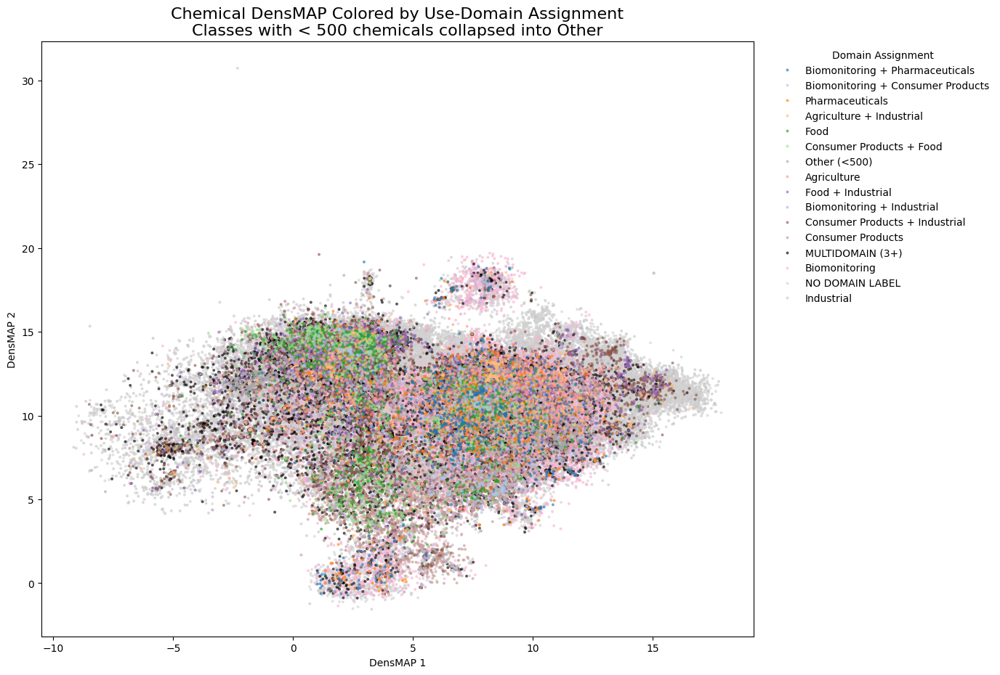

,domain_group,n_chemicals
0,Industrial,62102
1,NO DOMAIN LABEL,49127
2,Biomonitoring,16134
3,MULTIDOMAIN (3+),12933
4,Consumer Products,7335
5,Consumer Products + Industrial,5643
6,Biomonitoring + Industrial,3907
7,Food + Industrial,1772
8,Agriculture,1758
9,Other (<500),1665



Minimum class size retained: 500
Classes displayed: 16
Chemicals in Other (<500): 1,665


In [37]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

MIN_CLASS_SIZE = 500

# ------------------------------------------------------------
# Build plotting labels from use_domain_pivot
#
# 1 domain  -> Industrial
# 2 domains -> Industrial + Consumer Products
# >=3       -> MULTIDOMAIN (3+)
# ------------------------------------------------------------

domain_labels = use_domain_pivot.reset_index().copy()

def classify_domains(label_string):

    if pd.isna(label_string) or label_string == "":
        return "NO DOMAIN LABEL"

    domains = sorted(
        {
            x.strip()
            for x in str(label_string).split(",")
            if x.strip()
        }
    )

    if len(domains) == 1:
        return domains[0]

    if len(domains) == 2:
        return " + ".join(domains)

    return "MULTIDOMAIN (3+)"

domain_labels["plot_domain"] = (
    domain_labels["use_domain_labels"]
    .apply(classify_domains)
)

# ------------------------------------------------------------
# Merge onto fingerprints dataframe
# ------------------------------------------------------------

plot_df = fingerprints_df.copy()

plot_df = plot_df.merge(
    domain_labels[
        [
            "cichem_id",
            "plot_domain",
        ]
    ],
    left_on="cichem",
    right_on="cichem_id",
    how="left",
)

plot_df["plot_domain"] = (
    plot_df["plot_domain"]
    .fillna("NO DOMAIN LABEL")
)

# ------------------------------------------------------------
# Collapse rare classes
# ------------------------------------------------------------

original_counts = plot_df["plot_domain"].value_counts()

rare_classes = original_counts[
    original_counts < MIN_CLASS_SIZE
].index

plot_df["plot_domain"] = plot_df["plot_domain"].replace(
    rare_classes,
    "Other (<500)"
)

# ------------------------------------------------------------
# Counts after thresholding
# ------------------------------------------------------------

class_counts = (
    plot_df["plot_domain"]
    .value_counts(dropna=False)
    .sort_values(ascending=True)
)

category_order = class_counts.index.tolist()

display(
    class_counts
    .rename_axis("plot_domain")
    .reset_index(name="chemical_count")
)

# ------------------------------------------------------------
# Draw largest classes first so smaller ones remain visible
# ------------------------------------------------------------

plot_df["_class_count"] = (
    plot_df["plot_domain"]
    .map(class_counts)
)

plot_df_plot = (
    plot_df
    .sort_values("_class_count", ascending=False)
    .copy()
)

# ------------------------------------------------------------
# Palette
# ------------------------------------------------------------

base_palette = sns.color_palette(
    "tab20",
    n_colors=min(20, len(category_order))
)

extra_palette = sns.color_palette(
    "husl",
    n_colors=max(0, len(category_order) - len(base_palette))
)

colors = list(base_palette) + list(extra_palette)

palette = {
    label: color
    for label, color in zip(category_order, colors)
}

# Override specific categories

if "MULTIDOMAIN (3+)" in palette:
    palette["MULTIDOMAIN (3+)"] = "black"

if "NO DOMAIN LABEL" in palette:
    palette["NO DOMAIN LABEL"] = "lightgray"

if "Other (<500)" in palette:
    palette["Other (<500)"] = "darkgray"

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 10))

sns.scatterplot(
    data=plot_df_plot,
    x="densmap_1",
    y="densmap_2",
    hue="plot_domain",
    hue_order=category_order,
    palette=palette,
    s=8,
    alpha=0.65,
    linewidth=0,
    legend=True,
    ax=ax,
)

ax.set_title(
    f"Chemical DensMAP Colored by Use-Domain Assignment\n"
    f"Classes with < {MIN_CLASS_SIZE:,} chemicals collapsed into Other",
    fontsize=16,
)

ax.set_xlabel("DensMAP 1")
ax.set_ylabel("DensMAP 2")

sns.move_legend(
    ax,
    "upper left",
    bbox_to_anchor=(1.02, 1),
    title="Domain Assignment",
    frameon=False,
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.08,
    right=0.78,
    bottom=0.08,
    top=0.90,
)

fig.canvas.draw()

fig.savefig(
    "./figures/use_domain_densmap_project.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.25,
)

plt.show()

# ------------------------------------------------------------
# Summary table
# ------------------------------------------------------------

summary = (
    plot_df["plot_domain"]
    .value_counts()
    .rename_axis("domain_group")
    .reset_index(name="n_chemicals")
)

display(summary)

print(f"\nMinimum class size retained: {MIN_CLASS_SIZE:,}")
print(f"Classes displayed: {len(summary):,}")
print(
    f"Chemicals in Other (<500): "
    f"{summary.loc[summary['domain_group'] == 'Other (<500)', 'n_chemicals'].sum():,}"
    if (summary["domain_group"] == "Other (<500)").any()
    else "Chemicals in Other (<500): 0"
)

,superclass,chemical_count
0,Hydrocarbons,1510
1,Organosulfur compounds,1629
2,Organometallic compounds,1934
3,Organohalogen compounds,2233
4,Mixed metal/non-metal compounds,3672
5,Phenylpropanoids and polyketides,4638
6,Other (<1000),4727
7,Organic nitrogen compounds,5477
8,Organic oxygen compounds,9424
9,Lipids and lipid-like molecules,16004


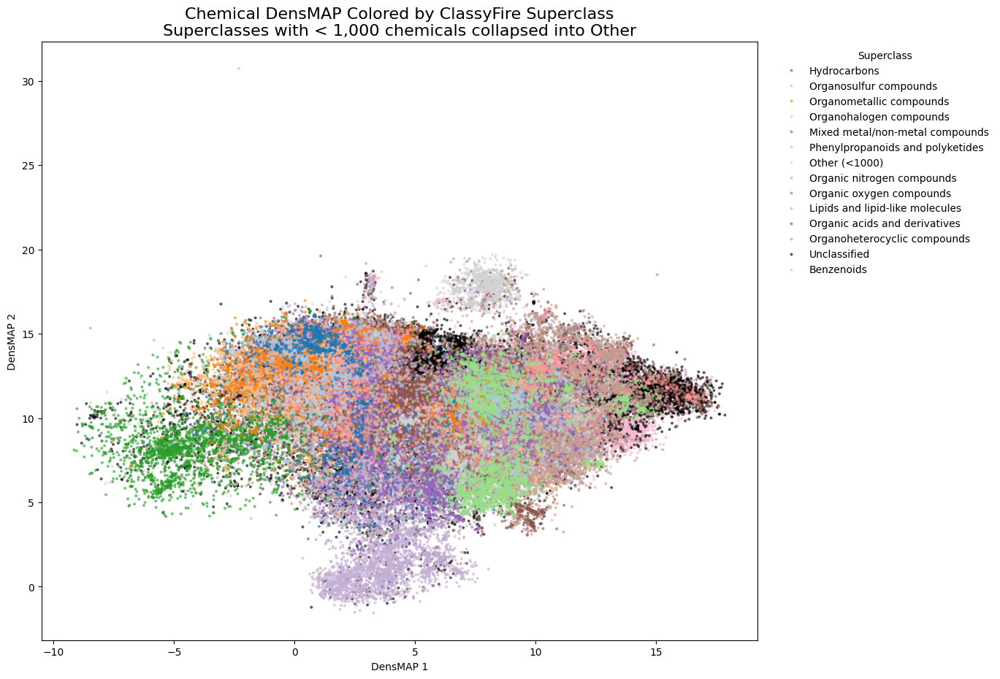

,superclass,chemical_count
0,Benzenoids,40492
1,Unclassified,31357
2,Organoheterocyclic compounds,26060
3,Organic acids and derivatives,18793
4,Lipids and lipid-like molecules,16004
5,Organic oxygen compounds,9424
6,Organic nitrogen compounds,5477
7,Other (<1000),4727
8,Phenylpropanoids and polyketides,4638
9,Mixed metal/non-metal compounds,3672



Minimum superclass size retained: 1,000
Displayed superclass categories: 14


In [38]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

MIN_CLASS_SIZE = 1000
OTHER_LABEL = f"Other (<{MIN_CLASS_SIZE})"

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

plot_df = classyfire.copy()

# Convert from categorical before introducing a new value
plot_df["superclass"] = (
    plot_df["superclass"]
    .astype("string")
    .fillna("Unclassified")
    .str.strip()
    .replace("", "Unclassified")
)

# ------------------------------------------------------------
# Collapse rare superclasses
# ------------------------------------------------------------

original_counts = plot_df["superclass"].value_counts()

rare_classes = original_counts[
    original_counts < MIN_CLASS_SIZE
].index

plot_df["superclass"] = (
    plot_df["superclass"]
    .replace(rare_classes, OTHER_LABEL)
)

# ------------------------------------------------------------
# Counts after thresholding
# ------------------------------------------------------------

class_counts = (
    plot_df["superclass"]
    .value_counts()
    .sort_values(ascending=True)
)

category_order = class_counts.index.tolist()

display(
    class_counts
    .rename_axis("superclass")
    .reset_index(name="chemical_count")
)

# ------------------------------------------------------------
# Draw large classes first
# ------------------------------------------------------------

plot_df["_class_count"] = plot_df["superclass"].map(class_counts)

plot_df_plot = (
    plot_df
    .sort_values("_class_count", ascending=False)
    .copy()
)

# ------------------------------------------------------------
# Palette
# ------------------------------------------------------------

base_palette = sns.color_palette(
    "tab20",
    n_colors=min(20, len(category_order))
)

extra_palette = sns.color_palette(
    "husl",
    n_colors=max(0, len(category_order) - len(base_palette))
)

colors = list(base_palette) + list(extra_palette)

palette = {
    label: color
    for label, color in zip(category_order, colors)
}

if OTHER_LABEL in palette:
    palette[OTHER_LABEL] = "lightgray"

if "Unclassified" in palette:
    palette["Unclassified"] = "black"

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 10))

sns.scatterplot(
    data=plot_df_plot,
    x="densmap_1",
    y="densmap_2",
    hue="superclass",
    hue_order=category_order,
    palette=palette,
    s=8,
    alpha=0.65,
    linewidth=0,
    legend=True,
    ax=ax,
)

ax.set_title(
    "Chemical DensMAP Colored by ClassyFire Superclass\n"
    f"Superclasses with < {MIN_CLASS_SIZE:,} chemicals collapsed into Other",
    fontsize=16,
)

ax.set_xlabel("DensMAP 1")
ax.set_ylabel("DensMAP 2")

sns.move_legend(
    ax,
    "upper left",
    bbox_to_anchor=(1.02, 1),
    title="Superclass",
    frameon=False,
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.08,
    right=0.78,
    bottom=0.08,
    top=0.90,
)

fig.savefig(
    "./figures/classyfire_superclass_densmap.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.25,
)

plt.show()

# ------------------------------------------------------------
# Summary table
# ------------------------------------------------------------

summary = (
    plot_df["superclass"]
    .value_counts()
    .rename_axis("superclass")
    .reset_index(name="chemical_count")
)

display(summary)

print(f"\nMinimum superclass size retained: {MIN_CLASS_SIZE:,}")
print(f"Displayed superclass categories: {len(summary):,}")

In [39]:
polymer_count = (
    fingerprints_df["primary_name"]
    .fillna("")
    .str.contains("polymer", case=False, regex=False)
    .sum()
)

print(f"{polymer_count:,} rows contain 'polymer' in primary_name")

5,404 rows contain 'polymer' in primary_name


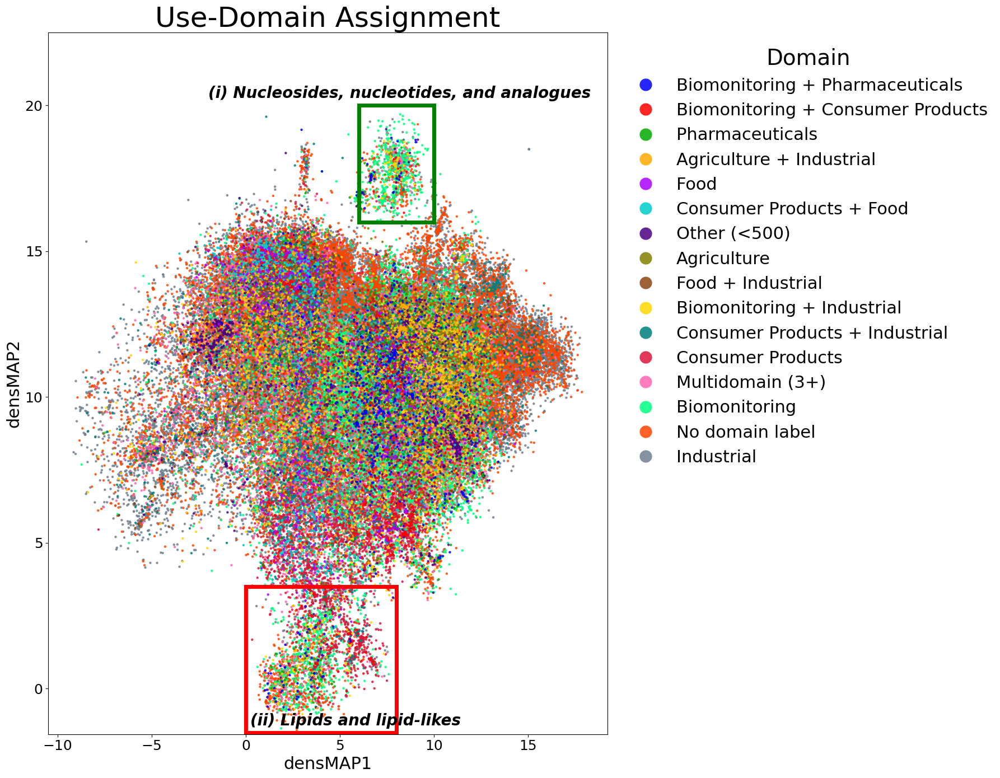

In [40]:
# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

MIN_DOMAIN_SIZE = 500

FIGURE_TITLE = 36
LEGEND_TEXT = 22
LEGEND_TITLE = 28

POINT_SIZE = 10
POINT_ALPHA = 0.85

# ------------------------------------------------------------
# Build use-domain dataframe
# ------------------------------------------------------------

domain_labels = use_domain_pivot.reset_index().copy()

def classify_domains(label_string):

    if pd.isna(label_string) or label_string == "":
        return "No domain label"

    domains = sorted(
        {
            x.strip()
            for x in str(label_string).split(",")
            if x.strip()
        }
    )

    if len(domains) == 1:
        return domains[0]

    if len(domains) == 2:
        return " + ".join(domains)

    return "Multidomain (3+)"

domain_labels["plot_domain"] = (
    domain_labels["use_domain_labels"]
    .apply(classify_domains)
)

domain_df = (
    fingerprints_df.copy()
    .merge(
        domain_labels[["cichem_id", "plot_domain"]],
        left_on="cichem",
        right_on="cichem_id",
        how="left",
    )
)

domain_df["plot_domain"] = (
    domain_df["plot_domain"]
    .fillna("No domain label")
)

# ------------------------------------------------------------
# Threshold classes
# ------------------------------------------------------------

domain_counts_raw = domain_df["plot_domain"].value_counts()

domain_df["plot_domain"] = domain_df["plot_domain"].replace(
    domain_counts_raw[domain_counts_raw < MIN_DOMAIN_SIZE].index,
    f"Other (<{MIN_DOMAIN_SIZE})",
)

domain_counts = domain_df["plot_domain"].value_counts()

domain_order = (
    domain_counts
    .sort_values(ascending=True)
    .index
    .tolist()
)

domain_df["_class_count"] = (
    domain_df["plot_domain"]
    .map(domain_counts)
)

domain_df_plot = (
    domain_df
    .sort_values("_class_count", ascending=False)
    .copy()
)

# ------------------------------------------------------------
# Palette
# ------------------------------------------------------------

glasbey_like = [
    "#0000FF",  # blue
    "#FF0000",  # red
    "#00AA00",  # green
    "#FFAA00",  # orange
    "#AA00FF",  # purple
    "#00CCCC",  # cyan
    "#FF66B2",  # pink
    "#808000",  # olive
    "#8B4513",  # brown
    "#FFD700",  # gold
    "#008080",  # teal
    "#DC143C",  # crimson
    "#4B0082",  # indigo
    "#00FF7F",  # spring green
    "#FF4500",  # orange red
    "#708090",  # slate gray
]

domain_palette = dict(
    zip(domain_order, glasbey_like[:len(domain_order)])
)

# Override special categories
domain_palette["Multidomain (3+)"] = "#FF66B2"
domain_palette["No domain label"] = "#FF4500"
domain_palette[f"Other (<{MIN_DOMAIN_SIZE})"] = "#4B0082"

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(18, 14)
)

sns.scatterplot(
    data=domain_df_plot,
    x="densmap_1",
    y="densmap_2",
    hue="plot_domain",
    hue_order=domain_order,
    palette=domain_palette,
    s=POINT_SIZE,
    alpha=POINT_ALPHA,
    linewidth=0,
    ax=ax,
)

ax.set_title(
    "Use-Domain Assignment",
    fontsize=FIGURE_TITLE,
)

ax.set_ylim(
    domain_df_plot["densmap_2"].min(),
    22.5,
)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

sns.move_legend(
    ax,
    "upper left",
    bbox_to_anchor=(1.01, 1.0),
    title="Domain",
    frameon=False,
    fontsize=LEGEND_TEXT,
    title_fontsize=LEGEND_TITLE,
)

leg = ax.get_legend()

if leg is not None:
    for h in leg.legend_handles:
        if hasattr(h, "set_markersize"):
            h.set_markersize(16)

# ------------------------------------------------------------
# Annotation boxes
# ------------------------------------------------------------

box1 = Rectangle(
    (0, -1.5),
    8.0,
    5.0,
    edgecolor="red",
    linewidth=5,
    fill=False,
)

box2 = Rectangle(
    (6.0, 16.0),
    4.0,
    4.0,
    edgecolor="green",
    linewidth=5,
    fill=False,
)

ax.add_patch(box1)
ax.add_patch(box2)

ax.text(
    0.25,
    -1.25,
    "(ii) Lipids and lipid-likes",
    fontsize=20,
    fontweight="bold",
    fontstyle="italic",
)

ax.text(
    -2.0,
    20.25,
    "(i) Nucleosides, nucleotides, and analogues",
    fontsize=20,
    fontweight="bold",
    fontstyle="italic",
)

ax.set_xlabel(
    "densMAP1",
    fontsize=22,
)

ax.set_ylabel(
    "densMAP2",
    fontsize=22,
)

ax.tick_params(
    axis="both",
    labelsize=18,   # adjust tick number size if desired
)

plt.tight_layout()

plt.savefig(
    "./figures/use_domain_assignment.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

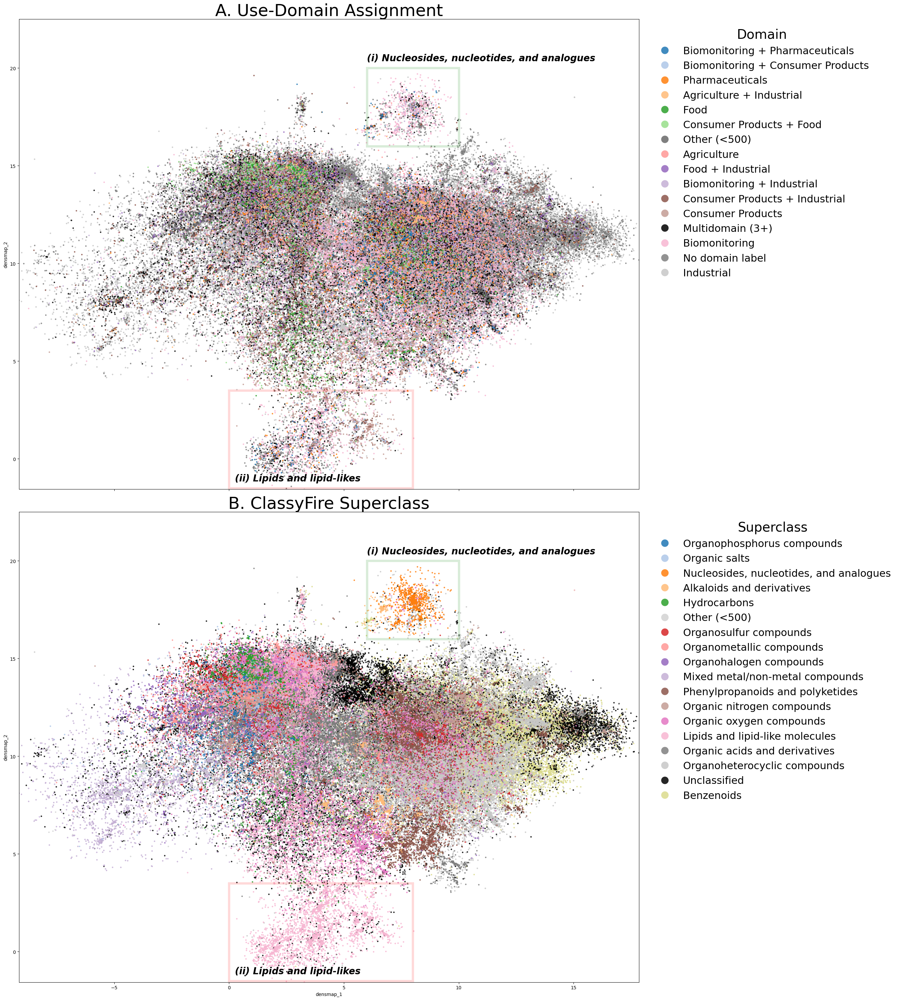

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from matplotlib.patches import Rectangle
# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

MIN_DOMAIN_SIZE = 500
MIN_SUPERCLASS_SIZE = 500

FIGURE_AXIS = 28          # axis label text
AXIS_TICK_SIZE = 22       # axis number text
FIGURE_TITLE = 36
LEGEND_TEXT = 22
LEGEND_TITLE = 28
SUPER_TITLE = 42

POINT_SIZE = 10
POINT_ALPHA = 0.85

# ------------------------------------------------------------
# Build use-domain dataframe
# ------------------------------------------------------------

domain_labels = use_domain_pivot.reset_index().copy()

def classify_domains(label_string):

    if pd.isna(label_string) or label_string == "":
        return "No domain label"

    domains = sorted(
        {
            x.strip()
            for x in str(label_string).split(",")
            if x.strip()
        }
    )

    if len(domains) == 1:
        return domains[0]

    if len(domains) == 2:
        return " + ".join(domains)

    return "Multidomain (3+)"

domain_labels["plot_domain"] = (
    domain_labels["use_domain_labels"]
    .apply(classify_domains)
)

domain_df = (
    fingerprints_df.copy()
    .merge(
        domain_labels[["cichem_id", "plot_domain"]],
        left_on="cichem",
        right_on="cichem_id",
        how="left",
    )
)

domain_df["plot_domain"] = (
    domain_df["plot_domain"]
    .fillna("No domain label")
)

# ------------------------------------------------------------
# Threshold domain classes
# ------------------------------------------------------------

domain_counts_raw = domain_df["plot_domain"].value_counts()

domain_df["plot_domain"] = domain_df["plot_domain"].replace(
    domain_counts_raw[domain_counts_raw < MIN_DOMAIN_SIZE].index,
    f"Other (<{MIN_DOMAIN_SIZE})",
)

domain_counts = domain_df["plot_domain"].value_counts()

domain_order = (
    domain_counts
    .sort_values(ascending=True)
    .index
    .tolist()
)

domain_df["_class_count"] = (
    domain_df["plot_domain"]
    .map(domain_counts)
)

domain_df_plot = (
    domain_df
    .sort_values("_class_count", ascending=False)
    .copy()
)

# ------------------------------------------------------------
# Build superclass dataframe
# ------------------------------------------------------------

super_df = classyfire.copy()

super_df["superclass"] = (
    super_df["superclass"]
    .astype("string")
    .fillna("Unclassified")
    .str.strip()
    .replace("", "Unclassified")
)

super_counts_raw = super_df["superclass"].value_counts()

super_df["superclass"] = super_df["superclass"].replace(
    super_counts_raw[super_counts_raw < MIN_SUPERCLASS_SIZE].index,
    f"Other (<{MIN_SUPERCLASS_SIZE})",
)

super_counts = super_df["superclass"].value_counts()

super_order = (
    super_counts
    .sort_values(ascending=True)
    .index
    .tolist()
)

super_df["_class_count"] = (
    super_df["superclass"]
    .map(super_counts)
)

super_df_plot = (
    super_df
    .sort_values("_class_count", ascending=False)
    .copy()
)

# ------------------------------------------------------------
# Color palettes
# ------------------------------------------------------------

domain_palette = dict(
    zip(
        domain_order,
        sns.color_palette(
            "tab20",
            n_colors=len(domain_order),
        ),
    )
)

if "Multidomain (3+)" in domain_palette:
    domain_palette["Multidomain (3+)"] = "black"

if "NO DOMAIN LABEL" in domain_palette:
    domain_palette["No domain label"] = "lightgray"

if f"Other (<{MIN_DOMAIN_SIZE})" in domain_palette:
    domain_palette[f"Other (<{MIN_DOMAIN_SIZE})"] = "dimgray"

super_palette = dict(
    zip(
        super_order,
        sns.color_palette(
            "tab20",
            n_colors=len(super_order),
        ),
    )
)

if "Unclassified" in super_palette:
    super_palette["Unclassified"] = "black"

if f"Other (<{MIN_SUPERCLASS_SIZE})" in super_palette:
    super_palette[f"Other (<{MIN_SUPERCLASS_SIZE})"] = "lightgray"

# ------------------------------------------------------------
# Shared axis limits
# ------------------------------------------------------------

xmin = min(
    domain_df_plot["densmap_1"].min(),
    super_df_plot["densmap_1"].min(),
)

xmax = max(
    domain_df_plot["densmap_1"].max(),
    super_df_plot["densmap_1"].max(),
)

ymin = min(
    domain_df_plot["densmap_2"].min(),
    super_df_plot["densmap_2"].min(),
)

ymax = 22.5

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(27, 30),
    sharex=True,
    sharey=True,
)

# ------------------------------------------------------------
# A. Use Domain Assignment
# ------------------------------------------------------------

sns.scatterplot(
    data=domain_df_plot,
    x="densmap_1",
    y="densmap_2",
    hue="plot_domain",
    hue_order=domain_order,
    palette=domain_palette,
    s=POINT_SIZE,
    alpha=POINT_ALPHA,
    linewidth=0,
    ax=axes[0],
)

axes[0].set_title(
    "A. Use-Domain Assignment",
    fontsize=FIGURE_TITLE,
)

axes[0].set_xlim(xmin, xmax)
axes[0].set_ylim(ymin, ymax)

sns.move_legend(
    axes[0],
    "upper left",
    bbox_to_anchor=(1.01, 1.0),
    title="Domain",
    frameon=False,
    fontsize=LEGEND_TEXT,
    title_fontsize=LEGEND_TITLE,
)

# ------------------------------------------------------------
# B. ClassyFire Superclass
# ------------------------------------------------------------

sns.scatterplot(
    data=super_df_plot,
    x="densmap_1",
    y="densmap_2",
    hue="superclass",
    hue_order=super_order,
    palette=super_palette,
    s=POINT_SIZE,
    alpha=POINT_ALPHA,
    linewidth=0,
    ax=axes[1],
)

axes[1].set_title(
    "B. ClassyFire Superclass",
    fontsize=FIGURE_TITLE,
)

axes[1].set_xlim(xmin, xmax)
axes[1].set_ylim(ymin, ymax)

sns.move_legend(
    axes[1],
    "upper left",
    bbox_to_anchor=(1.01, 1.0),
    title="Superclass",
    frameon=False,
    fontsize=LEGEND_TEXT,
    title_fontsize=LEGEND_TITLE,
)

for ax in axes:
    leg = ax.get_legend()

    if leg is not None:
        for h in leg.legend_handles:
            h.set_markersize(16)   # adjust as desired  

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------
for ax in axes:
    # Box 1
    x1, y1 = 0, -1.5
    w1, h1 = 8.0, 5.0

    box1 = Rectangle(
        (x1, y1),
        w1,
        h1,
        alpha=0.15,
        edgecolor="red",
        linewidth=5,
        fill=False,
    )

    # Box 2
    x2, y2 = 6.0, 16.0
    w2, h2 = 4.0, 4.0

    box2 = Rectangle(
        (x2, y2),
        w2,
        h2,
        alpha=0.15,
        edgecolor="green",
        linewidth=5,
        fill=False,
    )

    ax.add_patch(box1)
    ax.add_patch(box2)

    # Labels above upper-right corners
    ax.text(
        x1 + 0.25,
        y1 + 0.25,
        "(ii) Lipids and lipid-likes",
        ha="left",
        va="bottom",
        fontsize=20,
        fontweight="bold",
        fontstyle="italic",
        color="black",
    )

    ax.text(
        x2,
        y2 + h2 + 0.25,
        "(i) Nucleosides, nucleotides, and analogues",
        ha="left",
        va="bottom",
        fontsize=20,
        fontweight="bold",
        fontstyle="italic",
        color="black",
    )

fig.tight_layout()

fig.savefig(
    "./figures/densmap_AB_comparison.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.25,
)

plt.show()

In [42]:
import os
from urllib.parse import quote

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text


inactive_data = pd.read_parquet(r"./parquets/inactive_data.parquet")

In [43]:
curated_ids = set(
    curated_data["cichem_id"]
    .dropna()
    .drop_duplicates()
)

inactive_ids = set(
    inactive_data["cichem_id"]
    .dropna()
    .drop_duplicates()
)

intersection_ids = curated_ids & inactive_ids

print(f"Intersection size: {len(intersection_ids):,}")

Intersection size: 34,125


Shared chemicals: ((34125, 17),)
Tickets with >= 500 shared chemicals: 17
Tickets represented in the top combinations: 7


C:\Users\CharestNate\AppData\Local\Temp\ipykernel_17824\3116467025.py:202: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


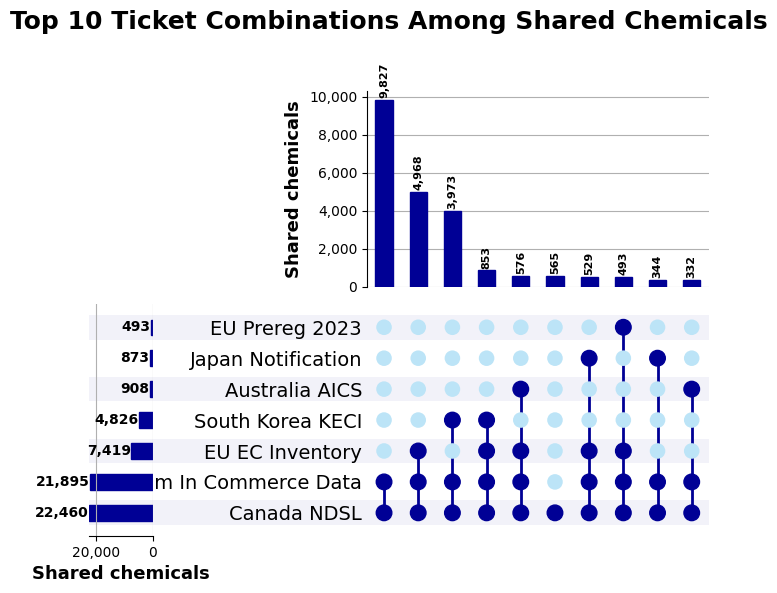

In [44]:
from upsetplot import UpSet
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
MIN_TICKET_SIZE = 500
TOP_N_COMBINATIONS = 10

# ------------------------------------------------------------
# Restrict to chemicals in the curated/inactive intersection
# ------------------------------------------------------------
shared_df = (
    curated_data.loc[
        curated_data["cichem_id"].isin(intersection_ids),
        ["cichem_id", "ticket_name"],
    ]
    .dropna(subset=["cichem_id", "ticket_name"])
    .drop_duplicates()
)

# ------------------------------------------------------------
# Build chemical x ticket membership matrix
# ------------------------------------------------------------
membership = (
    shared_df.assign(present=True)
    .pivot(
        index="cichem_id",
        columns="ticket_name",
        values="present",
    )
    .fillna(False)
    .astype(bool)
)

# Keep tickets containing at least MIN_TICKET_SIZE shared chemicals
ticket_sizes = membership.sum(axis=0)

keep_tickets = ticket_sizes[
    ticket_sizes >= MIN_TICKET_SIZE
].index

membership = membership.loc[:, keep_tickets]

if membership.shape[1] == 0:
    raise ValueError(
        f"No tickets contain at least {MIN_TICKET_SIZE:,} chemicals "
        "within intersection_ids."
    )

# ------------------------------------------------------------
# Count exact ticket-membership combinations
# observed=True avoids materializing unobserved combinations
# ------------------------------------------------------------
combo_counts = (
    membership
    .groupby(
        list(membership.columns),
        observed=True,
        sort=False,
    )
    .size()
    .sort_values(ascending=False)
    .head(TOP_N_COMBINATIONS)
)

# ------------------------------------------------------------
# Remove tickets that are absent from every top combination
# This prevents zero-count ticket rows from appearing in UpSet
# ------------------------------------------------------------
active_tickets = [
    ticket
    for ticket in combo_counts.index.names
    if combo_counts.index.get_level_values(ticket).any()
]

if not active_tickets:
    raise ValueError(
        "The selected combinations contain no positive ticket memberships. "
        "The dominant combination may be chemicals absent from every retained ticket."
    )

inactive_tickets = [
    ticket
    for ticket in combo_counts.index.names
    if ticket not in active_tickets
]

if inactive_tickets:
    combo_counts.index = combo_counts.index.droplevel(inactive_tickets)

# Defensive check: aggregate in case dropping unused levels creates duplicates
combo_counts = (
    combo_counts
    .groupby(level=list(range(combo_counts.index.nlevels)))
    .sum()
    .sort_values(ascending=False)
    .head(TOP_N_COMBINATIONS)
)

ticket_aliases = {
    "ROCKS_2026_I6a_eu-pre-reg-2023": "EU Prereg 2023",
    "ROCKS_2026_I7c_japan-notif" : "Japan Notification",
    "ROCKS_2026_I2_australia-aics" : "Australia AICS",
    "ROCKS_2026_I12_south-korea-keci" : "South Korea KECI",
    "ROCKS_2026_I6c_ec-inventory" : "EU EC Inventory",
    "ROCKS_2026_I16_vietnam-in-commerce" : "Vietnam In Commerce Data",
    "ROCKS_2026_I3b_canada-ndsl" : "Canada NDSL",
}

combo_counts.index = combo_counts.index.set_names(
    [ticket_aliases.get(name, name) for name in active_tickets]
)

print(f"Shared chemicals: {membership.shape,}")
print(f"Tickets with >= {MIN_TICKET_SIZE:,} shared chemicals: {len(keep_tickets):,}")
print(f"Tickets represented in the top combinations: {len(active_tickets):,}")


from matplotlib.ticker import StrMethodFormatter
from upsetplot import UpSet

fig = plt.figure(figsize=(20, 10))

upset = UpSet(
    combo_counts,
    subset_size="sum",
    sort_by="cardinality",
    show_counts="{:,.0f}",
    show_percentages=False,
    facecolor="#000095",
    other_dots_color="#BCE4F7",
)

axes = upset.plot(fig=fig)

# ----------------------------
# Intersection bars
# ----------------------------
axes["intersections"].set_ylabel(
    "Shared chemicals",
    fontsize=13,
    fontweight="bold",
)

axes["intersections"].yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

for txt in axes["intersections"].texts:
    txt.set_fontsize(8)
    txt.set_rotation(90)
    txt.set_fontweight("bold")
    txt.set_va("bottom")

# ----------------------------
# Set totals
# ----------------------------
axes["totals"].set_xlabel(
    "Shared chemicals",
    fontsize=13,
    fontweight="bold",
)

axes["totals"].xaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

for txt in axes["totals"].texts:
    txt.set_fontsize(10)
    txt.set_fontweight("bold")

# ----------------------------
# Matrix styling
# ----------------------------
axes["matrix"].tick_params(
    axis="y",
    labelsize=14,
    length=0,
)

axes["matrix"].set_xlabel("")

# ----------------------------
# Clean up spines
# ----------------------------
for ax in axes.values():
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# ----------------------------
# Title
# ----------------------------
fig.suptitle(
    "Top 10 Ticket Combinations Among Shared Chemicals",
    fontsize=18,
    fontweight="bold",
    y=1.02,
)

fig.tight_layout()

fig.savefig(
    "./figures/upset_inactive.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.25,
)

plt.show()

In [45]:
plot_df = pd.read_parquet(r"./parquets/chemical_property_data.parquet")
properties = pd.read_parquet(r"./parquets/properties.parquet")

logp_values = pd.read_parquet("./parquets/logp.parquet")
vp_values = pd.read_parquet("./parquets/vp.parquet")
bp_values = pd.read_parquet("./parquets/bp.parquet")
mp_values = pd.read_parquet("./parquets/mp.parquet")
ws_values = pd.read_parquet("./parquets/ws.parquet")
hlc_values = pd.read_parquet("./parquets/hlc.parquet")

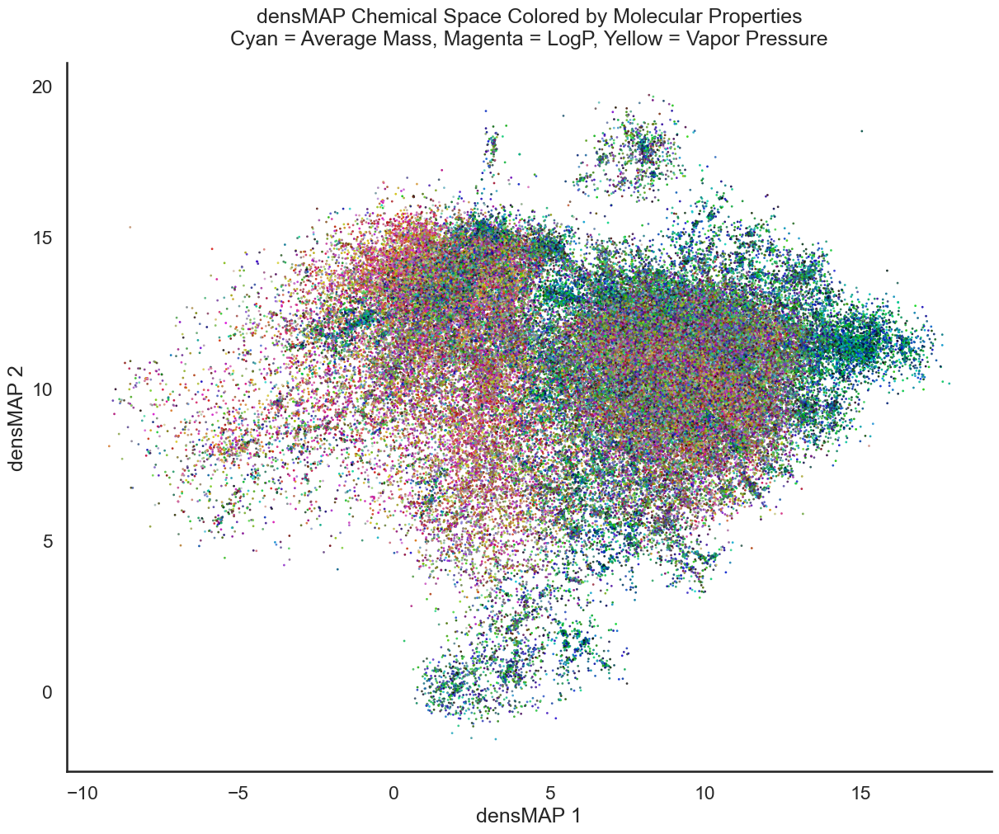

In [46]:
# ------------------------------------------------------------------
# 1. Merge coordinates and chemical properties
# ------------------------------------------------------------------
plot_df = (
    fingerprints_df
    .merge(
        properties,
        left_on="cichem",
        right_on="cichem_id",
        how="inner",
    )
    [
        [
            "cichem",
            "densmap_1",
            "densmap_2",
            "average_mass",
            "logp",
            "vp",
        ]
    ]
    .copy()
)

numeric_columns = [
    "densmap_1",
    "densmap_2",
    "average_mass",
    "logp",
    "vp",
]

plot_df[numeric_columns] = plot_df[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce",
)

plot_df = (
    plot_df
    .dropna(subset=numeric_columns)
    .reset_index(drop=True)
)

if plot_df.empty:
    raise ValueError(
        "No complete rows remain after removing missing coordinates "
        "and property values."
    )

# ------------------------------------------------------------------
# 2. Quantile-normalize each property to [0, 1]
#
# Cyan   = average mass
# Magenta = LogP
# Yellow  = vapor pressure
# ------------------------------------------------------------------
property_columns = [
    "average_mass",
    "logp",
    "vp",
]

qt = QuantileTransformer(
    n_quantiles=min(1000, len(plot_df)),
    output_distribution="uniform",
    random_state=42,
)

cmy = qt.fit_transform(plot_df[property_columns])

plot_df["cyan"] = cmy[:, 0]
plot_df["magenta"] = cmy[:, 1]
plot_df["yellow"] = cmy[:, 2]

# ------------------------------------------------------------------
# 3. Fix K and convert CMYK to RGB for Matplotlib
# ------------------------------------------------------------------
# K = 0.15 means even low-low-low observations are light gray rather
# than pure white. Increase K for a systematically darker palette.
fixed_k = 0.15

c = plot_df["cyan"].to_numpy()
m = plot_df["magenta"].to_numpy()
y = plot_df["yellow"].to_numpy()
k = np.full(len(plot_df), fixed_k)

# Standard CMYK-to-RGB conversion, with RGB values in [0, 1].
r = (1.0 - c) * (1.0 - k)
g = (1.0 - m) * (1.0 - k)
b = (1.0 - y) * (1.0 - k)

colors = np.column_stack([r, g, b])

plot_df["red_display"] = r
plot_df["green_display"] = g
plot_df["blue_display"] = b

# ------------------------------------------------------------------
# 4. Plot the densMAP embedding
# ------------------------------------------------------------------
sns.set_theme(
    style="white",
    context="talk",
)

fig, ax = plt.subplots(
    figsize=(12, 10),
    constrained_layout=True,
)

ax.scatter(
    plot_df["densmap_1"],
    plot_df["densmap_2"],
    c=colors,
    s=4,
    alpha=0.90,
    linewidths=0,
    rasterized=True,
)

ax.set_xlabel("densMAP 1")
ax.set_ylabel("densMAP 2")

ax.set_title(
    "densMAP Chemical Space Colored by Molecular Properties\n"
    "Cyan = Average Mass, Magenta = LogP, Yellow = Vapor Pressure",
    pad=16,
)

fig.savefig(
    "./figures/properties.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.25,
)

sns.despine(ax=ax)

plt.show()

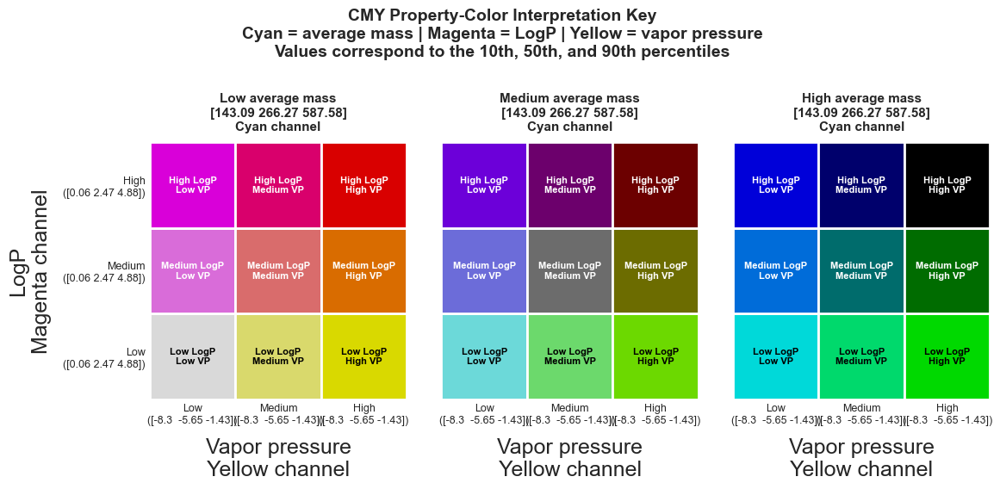

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ------------------------------------------------------------
# Compute representative values from the actual data
# ------------------------------------------------------------
quantiles = [0.10, 0.50, 0.90]
level_names = ["Low", "Medium", "High"]
channel_levels = [0.0, 0.5, 1.0]

mw_vals = np.round(plot_df["average_mass"].quantile(quantiles).to_numpy(), 2)
logp_vals = np.round(plot_df["logp"].quantile(quantiles).to_numpy(), 2)
vp_vals = np.round(plot_df["vp"].quantile(quantiles).to_numpy(), 2)

mw_labels = [
    f"Low\n({mw_vals})",
    f"Medium\n({mw_vals})",
    f"High\n({mw_vals})",
]

logp_labels = [
    f"Low\n({logp_vals})",
    f"Medium\n({logp_vals})",
    f"High\n({logp_vals})",
]

vp_labels = [
    f"Low\n({vp_vals})",
    f"Medium\n({vp_vals})",
    f"High\n({vp_vals})",
]

# ------------------------------------------------------------
# Fixed K for CMYK-inspired display
# This should match the value used in the densMAP figure.
# ------------------------------------------------------------
K = 0.15

# ------------------------------------------------------------
# Construct the legend figure
# ------------------------------------------------------------
fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(12, 5),
    sharex=True,
    sharey=True,
)

for panel_idx, ax in enumerate(axes):

    # Average mass controls the cyan channel.
    cyan = channel_levels[panel_idx]

    for row, magenta in enumerate(channel_levels):
        for col, yellow in enumerate(channel_levels):

            # CMYK -> RGB conversion for screen display.
            red = (1.0 - cyan) * (1.0 - K)
            green = (1.0 - magenta) * (1.0 - K)
            blue = (1.0 - yellow) * (1.0 - K)

            color = (red, green, blue)

            rectangle = Rectangle(
                xy=(col, row),
                width=1,
                height=1,
                facecolor=color,
                edgecolor="white",
                linewidth=2,
            )

            ax.add_patch(rectangle)

            # Select black or white annotation text based on
            # perceived display brightness.
            brightness = (
                0.2126 * red
                + 0.7152 * green
                + 0.0722 * blue
            )

            text_color = (
                "black"
                if brightness > 0.55
                else "white"
            )

            ax.text(
                col + 0.5,
                row + 0.5,
                f"{level_names[row]} LogP\n"
                f"{level_names[col]} VP",
                ha="center",
                va="center",
                fontsize=8,
                color=text_color,
                weight="bold",
            )

    ax.set_xlim(0, 3)
    ax.set_ylim(0, 3)
    ax.set_aspect("equal")

    ax.set_xticks(
        [0.5, 1.5, 2.5],
        labels=vp_labels,
    )

    ax.set_yticks(
        [0.5, 1.5, 2.5],
        labels=logp_labels,
    )

    ax.set_xlabel(
        "Vapor pressure\nYellow channel",
        labelpad=10,
    )

    ax.set_title(
        f"{level_names[panel_idx]} average mass\n"
        f"{mw_vals}\n"
        "Cyan channel",
        fontsize=11,
        weight="bold",
        pad=10,
    )

    ax.tick_params(
        axis="both",
        length=0,
        labelsize=9,
    )

    for spine in ax.spines.values():
        spine.set_visible(False)

axes[0].set_ylabel(
    "LogP\nMagenta channel",
    labelpad=10,
)

fig.suptitle(
    "CMY Property-Color Interpretation Key\n"
    "Cyan = average mass | Magenta = LogP | Yellow = vapor pressure\n"
    "Values correspond to the 10th, 50th, and 90th percentiles",
    fontsize=14,
    weight="bold",
    y=1.06,
)

fig.savefig(
    "./figures/properties_legend.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.25,
)

fig.tight_layout()
plt.show()

In [48]:
mw_values = plot_df.rename({'cichem' : 'cichem_id'}).set_index('cichem')

In [49]:
for df_name in ["bp_values", "mp_values", "ws_values", "hlc_values", "vp_values"]:
    globals()[df_name] = (
        globals()[df_name]
        .loc[lambda d: d["ad_reliability"].isin(["ambiguous", "reliable"])]
        .set_index("cichem_id")
    )

In [50]:
ws_values['ad_reliability'].value_counts()

ad_reliability
ambiguous     83541
reliable      73236
unreliable        0
Name: count, dtype: int64

In [51]:
state_df = pd.concat(
    [
        bp_values.add_prefix("bp_"),
        mp_values.add_prefix("mp_"),
        ws_values.add_prefix("ws_"),
        hlc_values.add_prefix("hlc_"),
        vp_values.add_prefix("vp_"),
        mw_values.add_prefix("mw_"),
    ],
    axis=1,
    join="outer",
)

state_df.index.name = "cichem_id"
screenable = state_df[['bp_bp', 'mp_mp', 'ws_ws', "hlc_hl", "vp_vp", "mw_average_mass"]].dropna()

screenable["ws_mg_L"] = (
    10 ** screenable["ws_ws"]
    * screenable["mw_average_mass"]
    * 1000
)

screenable

,bp_bp,mp_mp,ws_ws,hlc_hl,vp_vp,mw_average_mass,ws_mg_L
cichem_id,,,,,,,
CICHEM001854041,288.0,76.0,-4.17,-2.90,-2.11,194.182999,13.128380
CICHEM010987576,107.0,-87.0,-1.60,-2.60,1.54,3451.064941,86686.828125
CICHEM010987717,320.0,163.0,-2.39,-8.76,-5.61,1387.119995,5650.852051
CICHEM003357589,313.0,29.0,-4.95,-5.76,-3.67,246.354004,2.764139
CICHEM004804936,369.0,181.0,-3.01,-8.12,-7.24,186.199997,181.961563
...,...,...,...,...,...,...,...
CICHEM001763432,479.0,162.0,-2.63,-9.38,-7.24,390.450989,915.306152
CICHEM005560073,421.0,130.0,-5.45,-7.23,-4.37,101.105003,0.358734
CICHEM003465929,268.0,170.0,-3.68,-5.24,-7.07,221.259003,46.227547


In [52]:
gasses = screenable.loc[screenable['bp_bp'] < 25.0]
solids = screenable.loc[screenable['mp_mp'] >= 25.0]
liquids = screenable.loc[(screenable['bp_bp'] >= 25.0) & (state_df['mp_mp'] < 25.0)]

insoluble = screenable.loc[screenable['ws_mg_L'] <= 0.5]
volatile = screenable.loc[screenable['vp_vp'] >= np.log10(75)]
highly_volatile = screenable.loc[screenable['hlc_hl'] >= np.log10(0.1)]


In [53]:
import numpy as np
import pandas as pd

screenable = screenable.copy()

# ------------------------------------------------------------------
# Physical state at 25 C
# Gas takes precedence when BP < 25 C.
# Otherwise, solid requires MP >= 25 C.
# Liquid requires both BP and MP to support that assignment.
# ------------------------------------------------------------------
is_gas = (
    screenable["bp_bp"].notna()
    & screenable["bp_bp"].lt(25.0)
)

is_solid = (
    screenable["mp_mp"].notna()
    & screenable["mp_mp"].ge(25.0)
    & ~is_gas
)

is_liquid = (
    screenable["bp_bp"].notna()
    & screenable["mp_mp"].notna()
    & screenable["bp_bp"].ge(25.0)
    & screenable["mp_mp"].lt(25.0)
)

# ------------------------------------------------------------------
# Water solubility
# Do not define soluble as merely "not insoluble", because NaN would
# otherwise be treated as soluble.
# ------------------------------------------------------------------
is_insoluble = (
    screenable["ws_mg_L"].notna()
    & screenable["ws_mg_L"].le(0.5)
)

is_soluble = (
    screenable["ws_mg_L"].notna()
    & screenable["ws_mg_L"].gt(0.5)
)

# ------------------------------------------------------------------
# Volatility
# vp_vp is assumed to be log10(vapor pressure)
# hlc_hl is assumed to be log10(Henry's law constant)
# ------------------------------------------------------------------
is_volatile = (
    screenable["vp_vp"].notna()
    & screenable["vp_vp"].ge(np.log10(75))
)

is_nonvolatile = (
    screenable["vp_vp"].notna()
    & screenable["vp_vp"].lt(np.log10(75))
)

is_highly_volatile = (
    screenable["hlc_hl"].notna()
    & screenable["hlc_hl"].ge(np.log10(0.1))
)

# ------------------------------------------------------------------
# ABCD designation
# Order matters where definitions overlap:
# highly volatile gases receive D before soluble gases receive C.
# ------------------------------------------------------------------
conditions = [
    # A: insoluble solids
    is_solid & is_insoluble,

    # B: soluble solids or soluble non-volatile liquids
    (is_solid & is_soluble)
    | (is_liquid & is_soluble & is_nonvolatile),

    # D: insoluble gases or highly volatile gases
    (is_gas & is_insoluble)
    | (is_gas & is_highly_volatile),

    # C: soluble volatile liquids, insoluble liquids, or soluble gases
    (is_liquid & is_soluble & is_volatile)
    | (is_liquid & is_insoluble)
    | (is_gas & is_soluble),
]

screenable["designation"] = pd.Series(
    np.select(
        conditions,
        ["A", "B", "D", "C"],
        default=None,
    ),
    index=screenable.index,
    dtype="string",
)

screenable

,bp_bp,mp_mp,ws_ws,hlc_hl,vp_vp,mw_average_mass,ws_mg_L,designation
cichem_id,,,,,,,,
CICHEM001854041,288.0,76.0,-4.17,-2.90,-2.11,194.182999,13.128380,B
CICHEM010987576,107.0,-87.0,-1.60,-2.60,1.54,3451.064941,86686.828125,B
CICHEM010987717,320.0,163.0,-2.39,-8.76,-5.61,1387.119995,5650.852051,B
CICHEM003357589,313.0,29.0,-4.95,-5.76,-3.67,246.354004,2.764139,B
CICHEM004804936,369.0,181.0,-3.01,-8.12,-7.24,186.199997,181.961563,B
...,...,...,...,...,...,...,...,...
CICHEM001763432,479.0,162.0,-2.63,-9.38,-7.24,390.450989,915.306152,B
CICHEM005560073,421.0,130.0,-5.45,-7.23,-4.37,101.105003,0.358734,A
CICHEM003465929,268.0,170.0,-3.68,-5.24,-7.07,221.259003,46.227547,B


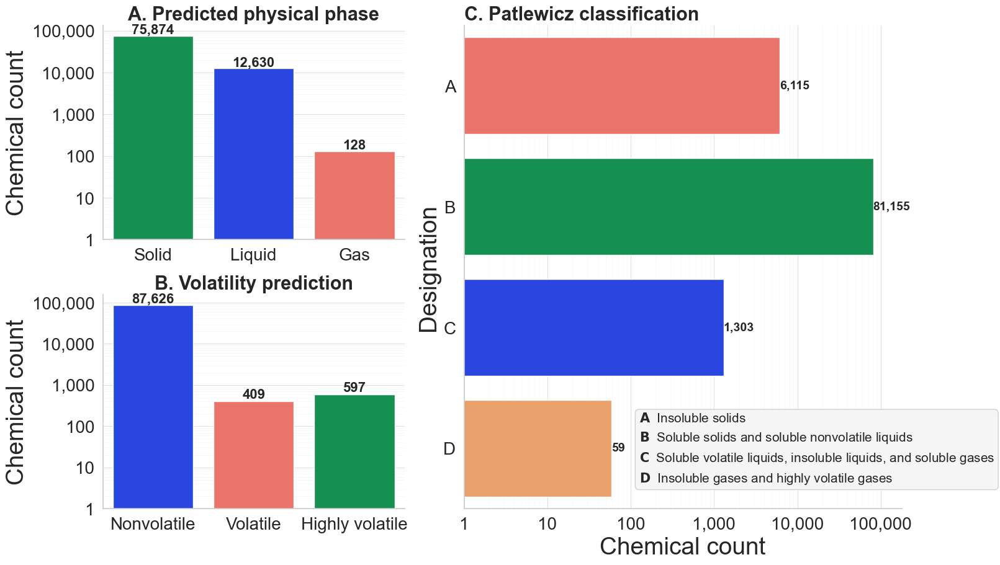

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from matplotlib.ticker import FuncFormatter, LogLocator

sns.set_theme(style="whitegrid", context="notebook")
SUBTITLE_FONT_SIZE = 22
# ------------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------------
def comma_log_formatter(value, position):
    """Format major log ticks as comma-separated integers."""
    if value >= 1:
        return f"{value:,.0f}"
    return f"{value:g}"


def annotate_vertical_bars(ax):
    """Add exact counts above vertical bars."""
    for bar in ax.patches:
        height = bar.get_height()

        if np.isfinite(height) and height > 0:
            ax.annotate(
                f"{height:,.0f}",
                xy=(
                    bar.get_x() + bar.get_width() / 2,
                    height,
                ),
                xytext=(0, 0),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=16,
                fontweight="bold",
            )


def annotate_horizontal_bars(ax):
    """Add exact counts to the right of horizontal bars."""
    for bar in ax.patches:
        width = bar.get_width()

        if np.isfinite(width) and width > 0:
            ax.annotate(
                f"{width:,.0f}",
                xy=(
                    width,
                    bar.get_y() + bar.get_height() / 2,
                ),
                xytext=(0, 0),
                textcoords="offset points",
                ha="left",
                va="center",
                fontsize=14,
                fontweight="bold",
            )


# ------------------------------------------------------------------
# Build mutually exclusive plotting categories
# ------------------------------------------------------------------

# Physical phase
phase = pd.Series(
    pd.NA,
    index=screenable.index,
    dtype="string",
)

phase.loc[is_gas] = "Gas"
phase.loc[is_solid] = "Solid"
phase.loc[is_liquid] = "Liquid"

phase_order = [
    "Solid",
    "Liquid",
    "Gas",
]

phase_counts = (
    phase
    .value_counts()
    .reindex(phase_order, fill_value=0)
)

phase_plot_df = (
    phase_counts
    .rename_axis("Phase")
    .rename("Count")
    .reset_index()
)

# Volatility
# Highly volatile takes precedence over the vapor-pressure categories.
volatility = pd.Series(
    pd.NA,
    index=screenable.index,
    dtype="string",
)

volatility.loc[
    is_nonvolatile & ~is_highly_volatile
] = "Nonvolatile"

volatility.loc[
    is_volatile & ~is_highly_volatile
] = "Volatile"

volatility.loc[
    is_highly_volatile
] = "Highly volatile"

volatility_order = [
    "Nonvolatile",
    "Volatile",
    "Highly volatile",
]

volatility_counts = (
    volatility
    .value_counts()
    .reindex(volatility_order, fill_value=0)
)

volatility_plot_df = (
    volatility_counts
    .rename_axis("Volatility")
    .rename("Count")
    .reset_index()
)

# ABCD designations
designation_order = [
    "A",
    "B",
    "C",
    "D",
]

designation_counts = (
    screenable["designation"]
    .value_counts()
    .reindex(designation_order, fill_value=0)
)

designation_plot_df = (
    designation_counts
    .rename_axis("Designation")
    .rename("Count")
    .reset_index()
)

# ------------------------------------------------------------------
# Palettes
# ------------------------------------------------------------------
phase_palette = {
    "Solid": "#00A451",
    "Liquid": "#0A32FF",
    "Gas": "#FF6255",
}

volatility_palette = {
    "Nonvolatile": "#0A32FF",
    "Volatile": "#FF6255",
    "Highly volatile": "#00A451",
}

designation_palette = {
    "A": "#FF6255",
    "B": "#00A451",
    "C": "#0A32FF",
    "D": "#FF9D55",
}

# ------------------------------------------------------------------
# Figure layout
# ------------------------------------------------------------------
fig = plt.figure(
    figsize=(16, 9),
    constrained_layout=True,
)

gs = fig.add_gridspec(
    nrows=2,
    ncols=2,
    width_ratios=[1.0, 1.45],
    height_ratios=[1, 1],
)

ax_a = fig.add_subplot(gs[0, 0])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[:, 1])

# ------------------------------------------------------------------
# A: Expected physical phase
# ------------------------------------------------------------------
sns.barplot(
    data=phase_plot_df,
    x="Phase",
    y="Count",
    hue="Phase",
    order=phase_order,
    hue_order=phase_order,
    palette=phase_palette,
    legend=False,
    errorbar=None,
    ax=ax_a,
)

ax_a.set_title(
    "A. Predicted physical phase",
    loc="center",
    fontsize=SUBTITLE_FONT_SIZE,
    fontweight="bold",
)

ax_a.set_xlabel("")
ax_a.set_ylabel("Chemical count")

ax_a.set_yscale("log")
ax_a.set_ylim(
    bottom=1,
    top=max(float(phase_counts.max()) * 1.8, 10),
)

ax_a.yaxis.set_major_locator(
    LogLocator(base=10)
)

ax_a.yaxis.set_major_formatter(
    FuncFormatter(comma_log_formatter)
)

annotate_vertical_bars(ax_a)

ax_a.grid(
    axis="y",
    which="major",
    linewidth=0.8,
    alpha=0.6,
)

ax_a.grid(
    axis="y",
    which="minor",
    linewidth=0.4,
    alpha=0.25,
)

ax_a.grid(axis="x", visible=False)

sns.despine(ax=ax_a)

# ------------------------------------------------------------------
# B: Volatility classification
# ------------------------------------------------------------------
sns.barplot(
    data=volatility_plot_df,
    x="Volatility",
    y="Count",
    hue="Volatility",
    order=volatility_order,
    hue_order=volatility_order,
    palette=volatility_palette,
    legend=False,
    errorbar=None,
    ax=ax_b,
)

ax_b.set_title(
    "B. Volatility prediction",
    loc="center",
    fontsize=SUBTITLE_FONT_SIZE,
    fontweight="bold",
)

ax_b.set_xlabel("")
ax_b.set_ylabel("Chemical count",)

ax_b.set_yscale("log")
ax_b.set_ylim(
    bottom=1,
    top=max(float(volatility_counts.max()) * 1.8, 10),
)

ax_b.yaxis.set_major_locator(
    LogLocator(base=10)
)

ax_b.yaxis.set_major_formatter(
    FuncFormatter(comma_log_formatter)
)

annotate_vertical_bars(ax_b)

ax_b.tick_params(
    axis="x",
)

ax_b.grid(
    axis="y",
    which="major",
    linewidth=0.8,
    alpha=0.6,
)

ax_b.grid(
    axis="y",
    which="minor",
    linewidth=0.4,
    alpha=0.25,
)

ax_b.grid(axis="x", visible=False)

sns.despine(ax=ax_b)

# ------------------------------------------------------------------
# C: ABCD designation allocation
# ------------------------------------------------------------------
sns.barplot(
    data=designation_plot_df,
    x="Count",
    y="Designation",
    hue="Designation",
    order=designation_order,
    hue_order=designation_order,
    palette=designation_palette,
    legend=False,
    errorbar=None,
    orient="h",
    ax=ax_c,
)

ax_c.set_title(
    "C. Patlewicz classification",
    loc="left",
    fontsize=SUBTITLE_FONT_SIZE,
    fontweight="bold",
)

ax_c.set_xlabel("Chemical count")
ax_c.set_ylabel("Designation")

ax_c.set_xscale("log")
ax_c.set_xlim(
    left=1,
    right=max(float(designation_counts.max()) * 2.2, 10),
)

ax_c.xaxis.set_major_locator(
    LogLocator(base=10)
)

ax_c.xaxis.set_major_formatter(
    FuncFormatter(comma_log_formatter)
)

annotate_horizontal_bars(ax_c)

ax_c.grid(
    axis="x",
    which="major",
    linewidth=0.8,
    alpha=0.6,
)

ax_c.grid(
    axis="x",
    which="minor",
    linewidth=0.4,
    alpha=0.25,
)

ax_c.grid(axis="y", visible=False)

sns.despine(ax=ax_c)


AXIS_LABEL_SIZE = 20
AXIS_TICK_SIZE = 20
for ax in [ax_a, ax_b, ax_c]:
    ax.tick_params(axis="both", labelsize=AXIS_TICK_SIZE)

    ax.set_xlabel(
        ax.get_xlabel(),
        fontsize=FIGURE_AXIS,
    )

    ax.set_ylabel(
        ax.get_ylabel(),
        fontsize=FIGURE_AXIS,
    )

# ------------------------------------------------------------------
# Classification definitions beneath Panel C
# ------------------------------------------------------------------
class_text = (
    r"$\bf{A}$  Insoluble solids"
    "\n"
    r"$\bf{B}$  Soluble solids and soluble nonvolatile liquids"
    "\n"
    r"$\bf{C}$  Soluble volatile liquids, insoluble liquids, and soluble gases"
    "\n"
    r"$\bf{D}$  Insoluble gases and highly volatile gases"
)

ax_c.text(
    0.40,
    0.20,
    class_text,
    transform=ax_c.transAxes,
    ha="left",
    va="top",
    fontsize=15.0,
    linespacing=1.5,
    bbox={
        "boxstyle": "round,pad=0.3",
        "facecolor": "#F5F5F5",
        "edgecolor": "#D0D0D0",
    },
)

# ------------------------------------------------------------------
# Overall title
# ------------------------------------------------------------------
classified_n = int(
    screenable["designation"].notna().sum()
)

unclassified_n = int(
    screenable["designation"].isna().sum()
)

fig.canvas.draw()

fig.savefig(
    "./figures/abcd_classification_summary.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()